In [8]:
print("Crop Disease Detection Project")
print("Our goal is to classify tomatoe leaf images")
print("We will use Pytorch to build our model")

Crop Disease Detection Project
Our goal is to classify tomatoe leaf images
We will use Pytorch to build our model


In [9]:
import torch
import torchvision
import matplotlib
from PIL import Image

print("Pytorch:", torch.__version__)
print("Torchvision:",torchvision.__version__)
print("Matplotlib:", matplotlib.__version__)
print("All basic image libraries imported successfully")

Pytorch: 2.14.0+cpu
Torchvision: 0.29.0+cpu
Matplotlib: 3.11.1
All basic image libraries imported successfully


In [10]:
%pip install datasets


Note: you may need to restart the kernel to use updated packages.


In [121]:
from datasets import load_dataset

dataset = load_dataset("manoela/plantvillage",split="train",streaming=True)
print(dataset)

IterableDataset({
    features: ['image', 'caption', 'captions'],
    num_shards: 1
})


In [12]:
example = next(iter(dataset))

print("Available fields:", example.keys())
print("\nCaption:", example["caption"])
print("\nCaptions:", example["captions"])
print("\nImage type:", type(example["image"]))
print("\nImage size:", example["image"].size)

Available fields: dict_keys(['image', 'caption', 'captions'])

Caption: Tomato healthy

Captions: ['A vibrant green and healthy tomato leaf with smooth, spotless surface.', 'A healthy Solanum lycopersicum leaf, free of disease or pests, with a uniform green color.', 'A fresh tomato leaf outdoors, glowing in sunlight with a smooth and unblemished surface.', 'A clean and healthy tomato leaf image, perfect for comparison in plant health datasets.']

Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>

Image size: (256, 256)


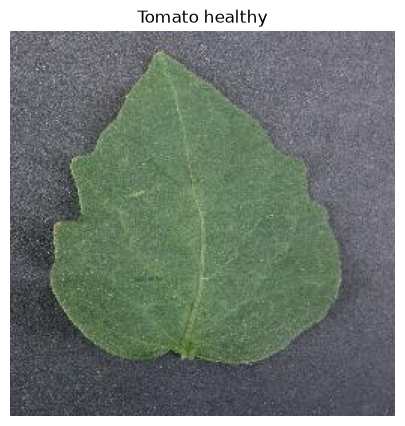

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(example["image"])
plt.title(example["caption"])
plt.axis("off")
plt.show()

In [14]:
from collections import Counter

label_counts = Counter()

for item in dataset:
    label_counts[item["caption"]] += 1
print("Number of categories:", len(label_counts))

for label, count in sorted(label_counts.items()):
    print(f"{label}: {count}")

Number of categories: 15
Pepper bell Bacterial spot: 997
Pepper bell healthy: 1478
Potato Early blight: 1000
Potato Late blight: 1000
Potato healthy: 152
Tomato Bacterial spot: 2127
Tomato Early blight: 1000
Tomato Late blight: 1909
Tomato Leaf Mold: 952
Tomato Septoria leaf spot: 1771
Tomato Spider mites Two spotted spider mite: 1676
Tomato Target Spot: 1404
Tomato YellowLeaf Curl Virus: 3208
Tomato healthy: 1591
Tomato mosaic virus: 373


In [15]:
from datasets import load_dataset

dataset = load_dataset("manoela/plantvillage",split="train",streaming=True)
print("Dataset stream refreshed.")

Dataset stream refreshed.


In [16]:
selected_labels = ["Tomato healthy","Tomato Early blight","Tomato Late blight"]

examples = {}

for item in dataset:
    label = item["caption"]
    if label in selected_labels and label not in examples:
        examples[label] = item

    if len(examples) == len(selected_labels):
        break

for label, item in examples.items():
    print(label, "—", item["image"].size)

Tomato healthy — (256, 256)
Tomato Late blight — (256, 256)
Tomato Early blight — (256, 256)


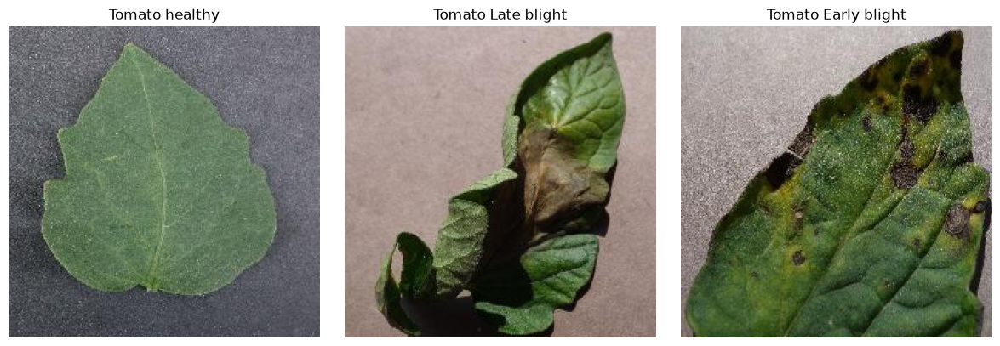

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (label, item) in zip(axes, examples.items()):
    ax.imshow(item["image"])
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
print("selected classes:", len(example,))
print("class names:", list(examples.keys()))      

selected classes: 3
class names: ['Tomato healthy', 'Tomato Late blight', 'Tomato Early blight']


In [19]:
from pathlib import Path
raw_data_dir = Path("..") / "data" / "raw"
raw_data_dir.mkdir(parents=True, exist_ok=True)
for label in examples :
    class_dir = raw_data_dir/label
    class_dir.mkdir(parents=True, exist_ok=True)
print("Class Folders Created Successfully")    

Class Folders Created Successfully


In [20]:
for folder in sorted(raw_data_dir.iterdir()):
    print(folder.name, "— folder:", folder.is_dir())

Tomato Early blight — folder: True
Tomato healthy — folder: True
Tomato Late blight — folder: True


In [21]:
from pathlib import Path

print("Current location:", Path.cwd())
print("Raw data location:", raw_data_dir.resolve())

Current location: C:\Users\pc\CropDiseaseDetection\notebooks
Raw data location: C:\Users\pc\CropDiseaseDetection\data\raw


In [22]:
for label,items in examples.items():
    class_dir = raw_data_dir/label
    image_path = class_dir/"sample.jpg"
    item["image"].save(image_path)
print("Sample Image Saved Successfully")    

Sample Image Saved Successfully


In [23]:
for label in examples:
    image_path = raw_data_dir / label / "sample.jpg"
    print(label, "— saved:", image_path.exists())

Tomato healthy — saved: True
Tomato Late blight — saved: True
Tomato Early blight — saved: True


In [24]:
from datasets import load_dataset
dataset= load_dataset("manoela/plantvillage", split= "train",streaming=True)
print(dataset)

IterableDataset({
    features: ['image', 'caption', 'captions'],
    num_shards: 1
})


In [25]:
selected_labels = ["Tomato healthy", "Tomato Late blight", "Tomato Early blight"]
count = 0
for item in dataset:
    if item["caption"] in selected_labels:
        print(item["caption"])
        count +=1
        if count == 10:
         break

Tomato healthy
Tomato Late blight
Tomato healthy
Tomato Early blight
Tomato healthy
Tomato Early blight
Tomato Late blight
Tomato healthy
Tomato Early blight
Tomato Late blight


In [42]:
max_images = 5
counts = {"Tomato healthy":0, "Tomato Late blight":0, "Tomato healthy":0}

In [27]:
count=0
for item in dataset:
    label = item["caption"]
    if label in counts:
        print(label)
        count +=1
        if count == 5:
            break

Tomato healthy
Tomato Late blight
Tomato healthy
Tomato healthy
Tomato Late blight


In [28]:
from datasets import load_dataset

dataset = load_dataset(
    "manoela/plantvillage",
    split="train",
    streaming=True
)

print("Dataset stream is ready.")

Dataset stream is ready.


In [29]:
for label in counts:
    class_dir = raw_data_dir/label
    print(label)
    print("Folder Exist:", class_dir.exists())
    print("Files:", list(class_dir.iterdir()))
    print()

Tomato healthy
Folder Exist: True
Files: [WindowsPath('../data/raw/Tomato healthy/image_0001.jpg'), WindowsPath('../data/raw/Tomato healthy/sample.jpg')]

Tomato Late blight
Folder Exist: True
Files: [WindowsPath('../data/raw/Tomato Late blight/sample.jpg')]



In [30]:
from pathlib import Path

raw_data_dir = Path("..") / "data" / "raw"

print("Raw data location:", raw_data_dir.resolve())
print("Folder exists:", raw_data_dir.exists())

Raw data location: C:\Users\pc\CropDiseaseDetection\data\raw
Folder exists: True


In [31]:
for label in counts:
    class_dir = raw_data_dir/label
    print(label)
    print("Folder Exist:", class_dir.exists())
    print("Files:", list(class_dir.iterdir()))
    print()

Tomato healthy
Folder Exist: True
Files: [WindowsPath('../data/raw/Tomato healthy/image_0001.jpg'), WindowsPath('../data/raw/Tomato healthy/sample.jpg')]

Tomato Late blight
Folder Exist: True
Files: [WindowsPath('../data/raw/Tomato Late blight/sample.jpg')]



In [32]:
selected_labels = [
    "Tomato healthy",
    "Tomato Early blight",
    "Tomato Late blight"
]

for label in selected_labels:
    class_dir = raw_data_dir / label

    print(label)
    print("Folder exists:", class_dir.exists())

    if class_dir.exists():
        print("Files:", [file.name for file in class_dir.iterdir()])

    print()

Tomato healthy
Folder exists: True
Files: ['image_0001.jpg', 'sample.jpg']

Tomato Early blight
Folder exists: True
Files: ['sample.jpg']

Tomato Late blight
Folder exists: True
Files: ['sample.jpg']



In [33]:
from datasets import load_dataset

dataset = load_dataset(
    "manoela/plantvillage",
    split="train",
    streaming=True
)

print("Fresh dataset stream ready.")

Fresh dataset stream ready.


In [34]:
from pathlib import Path

raw_data_dir = Path("..") / "data" / "raw"

for label in [
    "Tomato healthy",
    "Tomato Early blight",
    "Tomato Late blight"
]:
    class_dir = raw_data_dir / label
    print(label, ":", list(class_dir.glob("*.jpg")))

Tomato healthy : [WindowsPath('../data/raw/Tomato healthy/image_0001.jpg'), WindowsPath('../data/raw/Tomato healthy/sample.jpg')]
Tomato Early blight : [WindowsPath('../data/raw/Tomato Early blight/sample.jpg')]
Tomato Late blight : [WindowsPath('../data/raw/Tomato Late blight/sample.jpg')]


In [44]:
max_images =5
counts = {"Tomato healthy":0, "Tomato Late blight":0, "Tomato Early blight":0}
for item in dataset:
    if label in counts and counts[label] < max_images:
        image = item["image"]
        counts[label] +=1
        filename = f"image_{counts[label]:04d}.jpg"
        save_path = raw_data_dir/ label / filename
        image.save(save_path)
    if all(count==max_images for count in counts.values()):
          break
print("Saved image:", counts)        

Saved image: {'Tomato healthy': 0, 'Tomato Late blight': 5, 'Tomato Early blight': 0}


In [36]:
from pathlib import Path

raw_data_dir = Path("..") / "data" / "raw"

for label in ["Tomato healthy","Tomato Early blight","Tomato Late blight"]:
    class_dir = raw_data_dir / label
    print(label, ":", list(class_dir.glob("*.jpg")))

Tomato healthy : [WindowsPath('../data/raw/Tomato healthy/image_0001.jpg'), WindowsPath('../data/raw/Tomato healthy/sample.jpg')]
Tomato Early blight : [WindowsPath('../data/raw/Tomato Early blight/sample.jpg')]
Tomato Late blight : [WindowsPath('../data/raw/Tomato Late blight/image_0001.jpg'), WindowsPath('../data/raw/Tomato Late blight/sample.jpg')]


In [37]:
from PIL import Image
image_path = raw_data_dir / "Tomato healthy" / "sample.jpg"
image = Image.open(image_path)
print("Image type:", type(image))
print("Image size:", image.size)
print("Image mode:", image.mode)

Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (256, 256)
Image mode: RGB


In [38]:
import os

os.environ["HF_HUB_ETAG_TIMEOUT"] = "60"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"

from datasets import load_dataset

dataset = load_dataset(
    "manoela/plantvillage",
    split="train",
    streaming=True
)

print("Dataset stream initialized.")

Dataset stream initialized.


In [45]:
max_images =5
counts = {"Tomato healthy":0, "Tomato Late blight":0, "Tomato Early blight":0}
for item in dataset:
    if label in counts and counts[label] < max_images:
        image = item["image"]
        counts[label] +=1
        filename = f"image_{counts[label]:04d}.jpg"
        save_path = raw_data_dir/ label / filename
        image.save(save_path)
    if all(count==max_images for count in counts.values()):
          break
print("Saved image:", counts)        

Saved image: {'Tomato healthy': 0, 'Tomato Late blight': 5, 'Tomato Early blight': 0}


In [51]:
from torchvision import transforms
to_tensor = transforms.ToTensor()
image_tensor = to_tensor(image)
print("Image size:", type(image_tensor))
print("image shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Image size: <class 'torch.Tensor'>
image shape: torch.Size([3, 256, 256])
Tensor data type: torch.float32
Minimum value: 0.0
Maximum value: 1.0


In [52]:
print("Red channel value:", image_tensor[0, 0, 0])
print("Green channel value:", image_tensor[1, 0, 0])
print("Blue channel value:", image_tensor[2, 0, 0])

Red channel value: tensor(0.7490)
Green channel value: tensor(0.7255)
Blue channel value: tensor(0.7725)


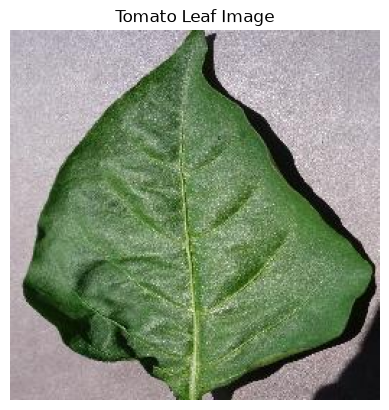

In [53]:
import matplotlib.pyplot as plt
image_display = image_tensor.permute(1,2,0)
plt.imshow(image_display)
plt.title("Tomato Leaf Image")
plt.axis("off")
plt.show()

In [54]:
print("Original tensor shape:", image_tensor.shape)

image_display = image_tensor.permute(1, 2, 0)

print("Display image shape:", image_display.shape)

Original tensor shape: torch.Size([3, 256, 256])
Display image shape: torch.Size([256, 256, 3])


In [55]:
import torchvision
from torchvision import transforms
Resize_Transform = transforms.Resize((128,128))
image_resize = Resize_Transform(image)
print("My resized image:", image_resize.size)

My resized image: (128, 128)


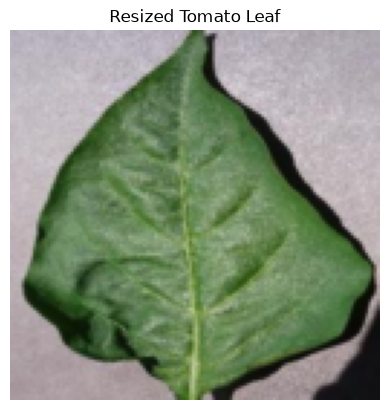

In [57]:
import matplotlib.pyplot as plt

plt.imshow(image_resize)
plt.title("Resized Tomato Leaf")
plt.axis("off")
plt.show()

In [58]:
Preprocess= transforms.Compose([transforms.Resize((128,128)), transforms.ToTensor(), transforms.Normalize(mean=(0.5,0.5,0.5), std=(0.25, 0.25, 0.25))])
image_tensor_128 = Preprocess(image)
print("Tensor shape:", image_tensor_128.shape)
print("Tensor type:", type(image_tensor_128))


Tensor shape: torch.Size([3, 128, 128])
Tensor type: <class 'torch.Tensor'>


In [59]:
print("Shape:", image_tensor_128.shape)
print("Minimum:", image_tensor_128.min().item())
print("Maximum:", image_tensor_128.max().item())

Shape: torch.Size([3, 128, 128])
Minimum: -2.0
Maximum: 1.4039216041564941


In [60]:
from torchvision import transforms
Prepro =transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(), transforms.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5))])
image_tensor_64=Prepro(image)
print("Shape:", image_tensor_64.shape)
print("Minimum:", image_tensor_64.min().item())
print("Data Type:", image_tensor_64.dtype)
print("Maximum:", image_tensor_64.max().item())

Shape: torch.Size([3, 64, 64])
Minimum: -0.9764705896377563
Data Type: torch.float32
Maximum: 0.615686297416687


In [61]:
from pathlib import Path

raw_data_dir = Path("..") / "data" / "raw"

for folder in raw_data_dir.iterdir():
    if folder.is_dir():
        print(folder.name)
        print("Images:", len(list(folder.glob("*.jpg"))))

Tomato Early blight
Images: 1
Tomato healthy
Images: 2
Tomato Late blight
Images: 6


In [62]:
from pathlib import Path

raw_data_dir = Path("..") / "data" / "raw"

class_names = [
    "Tomato Early blight",
    "Tomato healthy",
    "Tomato Late blight"
]

for label, class_name in enumerate(class_names):
    class_dir = raw_data_dir / class_name
    print(label, class_name, class_dir.exists())

0 Tomato Early blight True
1 Tomato healthy True
2 Tomato Late blight True


In [69]:

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

class_names = ["Tomato healthy","Tomato Early blight", "Tomato Late blight"]

class TomatoDataset(Dataset):

    def __init__(self, data_dir, transform=None):
        self.data_dir = Path(data_dir)
        self.transform = transform
        self.samples = []

        for label, class_name in enumerate(class_names):
            class_dir = self.data_dir / class_name

            for image_path in class_dir.glob("*.jpg"):
                self.samples.append((image_path, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]
        image = Image.open(image_path).convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label


In [70]:
raw_data_dir = Path("..")/ "data"/"raw"
tomato_dataset = TomatoDataset(raw_data_dir)
print(len(tomato_dataset))

9


In [71]:
sample = tomato_dataset[0]

print(sample)
print(type(sample))

(<PIL.Image.Image image mode=RGB size=256x256 at 0x23F873DF170>, 0)
<class 'tuple'>


In [72]:
sample = tomato_dataset[0]
image_sample = sample[0]
label_sample = sample[1]
print(sample)
print(label_sample)
print("Image type:", type(image_sample))
print("Image size:", image_sample.size)
print("Label:", label_sample)

(<PIL.Image.Image image mode=RGB size=256x256 at 0x23F852D63C0>, 0)
0
Image type: <class 'PIL.Image.Image'>
Image size: (256, 256)
Label: 0


In [73]:
preprocess= transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(),transforms.Normalize(mean=(0.5,0.5,0.5), std=(0.5,0.5,0.5))])
tomato_dataset= TomatoDataset(data_dir= raw_data_dir, transform= preprocess)
sample = tomato_dataset[0]
image_sampl = sample[0]
label_sampl = sample[1]
print("image Type:", type(image_sampl))
print("image shape:", image_sampl.shape)
print(label_sampl)

image Type: <class 'torch.Tensor'>
image shape: torch.Size([3, 64, 64])
0


In [74]:
print("Data Type:", image_sampl.dtype)
print("Maximum value:", image_sampl.max().item())
print("Minimum Value:", image_sampl.min().item())

Data Type: torch.float32
Maximum value: 0.18431377410888672
Minimum Value: -0.6078431606292725


In [75]:
from torch.utils.data import DataLoader
tomato_loader = DataLoader(tomato_dataset, batch_size=2, shuffle=True)
batch = (next(iter(tomato_loader)))
image_batch = batch[0]
labels_batch = batch[1]
print("Image Shape:", image_batch.shape)
print(labels_batch)

Image Shape: torch.Size([2, 3, 64, 64])
tensor([2, 2])


In [77]:
print(len(tomato_dataset))
print(len(tomato_loader))

9
5


In [78]:
for batch in tomato_loader:
    images = batch[0]
    labels = batch[1]
    print("Image Shape:",images.shape)
    print("Label:", labels)
    

Image Shape: torch.Size([2, 3, 64, 64])
Label: tensor([2, 0])
Image Shape: torch.Size([2, 3, 64, 64])
Label: tensor([0, 2])
Image Shape: torch.Size([2, 3, 64, 64])
Label: tensor([2, 2])
Image Shape: torch.Size([2, 3, 64, 64])
Label: tensor([2, 2])
Image Shape: torch.Size([1, 3, 64, 64])
Label: tensor([1])


In [79]:
batch_count = 0
for batch in tomato_loader:
    images = batch[0]
    labels = batch[1]
    batch_count+=1
print("Number of Bathces:", batch_count)

Number of Bathces: 5


In [80]:
test_loader = DataLoader(tomato_dataset,batch_size=3,shuffle=True, drop_last =True)
print(len(test_loader))

3


In [81]:
for batch in test_loader:
    images = batch[0]
    labels = batch[1]
    print("Image Shape:", images.shape)
    print("labels:", labels)

Image Shape: torch.Size([3, 3, 64, 64])
labels: tensor([2, 2, 2])
Image Shape: torch.Size([3, 3, 64, 64])
labels: tensor([0, 2, 2])
Image Shape: torch.Size([3, 3, 64, 64])
labels: tensor([1, 2, 0])


In [82]:
import torch.nn as nn
class TomatoCNN(nn.Module):
    def __init__(self):
      super().__init__()
      self.conv1= nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
      self.relu1 = nn.ReLU()
      self.maxpool1 = nn.MaxPool2d(kernel_size=2, stride=2)
      self.conv2 = nn.Conv2d(in_channels=16, out_channels= 32, kernel_size=3, padding=1)
      self.relu2= nn.ReLU()
      self.maxpool2= nn.MaxPool2d(kernel_size=2, stride=2)
      self.conv3 = nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1)
      self.relu3 = nn.ReLU()
      self.maxpool3 = nn.MaxPool2d(kernel_size=2,stride=2)  
      self.flatten = nn.Flatten()
      self.fc1 = nn.Linear(in_features= 4096, out_features=128)
      self.relu4 = nn.ReLU()
      self.dropout = nn.Dropout(p=0.5)
      self.fc2  =nn.Linear(in_features=128, out_features=3)

    def forward(self,x):
        conv1 = self.conv1(x)
        relu1 = self.relu1(conv1)
        maxpool1= self.maxpool1(relu1)
        conv2 = self.conv2(maxpool1)
        relu2 = self.relu2(conv2)
        maxpool2 = self.maxpool2(relu2)
        conv3 = self.conv3(maxpool2)
        relu3= self.relu3(conv3)
        maxpool3= self.maxpool3(relu3)
        flatten= self.flatten(maxpool3)
        fc1 = self.fc1(flatten)
        relu4= self.relu4(fc1)
        dropout = self.dropout(relu4)
        fc2= self.fc2(dropout)
        return fc2

In [83]:
model = TomatoCNN()
images, labels = next(iter(tomato_loader))
outputs=model(images)
print(outputs.shape)
print(outputs)

torch.Size([2, 3])
tensor([[0.0276, 0.0765, 0.0307],
        [0.0329, 0.1031, 0.0193]], grad_fn=<AddmmBackward0>)


In [84]:
predictions = torch.argmax(outputs, dim=1)
print(predictions)

tensor([1, 1])


In [85]:
import torch
scores= torch.tensor([1.8, 0.5, 3.2, 2.4, 0.9])
print(torch.max(scores))
print(torch.argmax(scores))
print(type(scores))
print(scores[0])
print(scores[2])
print(scores[-1])

tensor(3.2000)
tensor(2)
<class 'torch.Tensor'>
tensor(1.8000)
tensor(3.2000)
tensor(0.9000)


In [86]:
import torch
predictions = torch.tensor([0.2,0.7,0.1])
print(torch.max(predictions))
print(torch.argmax(predictions))
print(predictions[1])
print(torch.argmax(predictions, dim=0))
outputs = torch.tensor([[0.1, 0.2, 0.7],[0.9, 0.05, 0.05],[0.2, 0.3, 0.5]])
predicted_classes = outputs

tensor(0.7000)
tensor(1)
tensor(0.7000)
tensor(1)


In [87]:
outputs = torch.tensor([[0.1, 0.2, 0.7],[0.9, 0.05, 0.05],[0.2, 0.3, 0.5]])
print(torch.argmax(outputs, dim=1))
predicted_classes = torch.argmax(outputs, dim=1)
print(predicted_classes)
print(predicted_classes[1])
class_names = ["Tomato Early blight","Tomato healthy","Tomato Late blight"]
print(class_names)
print(type(class_names))
for i in range(len(predicted_classes)):
    print(f"Image {i + 1}: {class_names[predicted_classes[i]]}" )

tensor([2, 0, 2])
tensor([2, 0, 2])
tensor(0)
['Tomato Early blight', 'Tomato healthy', 'Tomato Late blight']
<class 'list'>
Image 1: Tomato Late blight
Image 2: Tomato Early blight
Image 3: Tomato Late blight


In [88]:
import torch.nn as nn
criterion = nn.CrossEntropyLoss()
print(criterion)
outputs = torch.tensor([[0.2, 0.3, 2.1],[2.5, 0.4, 0.1]])
labels = torch.tensor([2, 0])
print(f"Outputs shape:", outputs.shape)
print(f"Labels shape:", labels.shape)
print(f"Labels data type:", labels.dtype)

CrossEntropyLoss()
Outputs shape: torch.Size([2, 3])
Labels shape: torch.Size([2])
Labels data type: torch.int64


In [89]:
loss = criterion(outputs, labels)
print(loss)

tensor(0.2335)


In [90]:



from torch.utils.data import random_split

# Calculate dataset sizes
total_size = len(tomato_dataset)

train_size = int(0.8 * total_size)
val_size = total_size - train_size

# Split the dataset
train_dataset, val_dataset = random_split(tomato_dataset,[train_size, val_size],generator=torch.Generator().manual_seed(42))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 7
Validation images: 2


In [92]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset,batch_size=2,shuffle=True)

val_loader = DataLoader(val_dataset,batch_size=2,shuffle=False)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 4
Validation batches: 1


In [94]:
import torch.optim as optim
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [95]:
num_epochs = 10

for epoch in range(num_epochs):

    # =========================
    # 1. TRAINING
    # =========================
    model.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_total += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_total / train_total
    train_accuracy = 100 * train_correct / train_total

    # =========================
    # 2. VALIDATION
    # =========================
    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_total += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_total / val_total
    val_accuracy = 100 * val_correct / val_total
best_val_loss = float("inf")

# Inside your training loop, after calculating val_loss:

if val_loss < best_val_loss:
    best_val_loss = val_loss
    torch.save(model.state_dict(),"best_model.pth")
    # =========================
    # 3. DISPLAY RESULTS
    # =========================
    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")
    print("-" * 50)
    print("Best model saved!")

Epoch [10/10]
Train Loss: 0.2886 | Train Accuracy: 85.71%
Val Loss: 12.5789 | Val Accuracy: 0.00%
--------------------------------------------------
Best model saved!


In [96]:
import torch

model = TomatoCNN()

model.load_state_dict(torch.load("best_model.pth",map_location="cpu",weights_only=True))

model.eval()
print("Trained model restored successfully!")

Trained model restored successfully!


In [97]:
# Save the model's learned parameters
torch.save(model.state_dict(), "best_model.pth")

print("Model saved successfully!")
# Create the same model architecture
model = TomatoCNN()

# Load the saved parameters
model.load_state_dict(torch.load("best_model.pth", map_location="cpu", weights_only=True))

# Set evaluation mode
model.eval()

print("Model loaded successfully!")

Model saved successfully!
Model loaded successfully!


In [98]:
model.load_state_dict(torch.load("best_model.pth", map_location="cpu", weights_only=True))
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
        
test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 66.67%


In [1]:
import torch
import sklearn

print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)


PyTorch: 2.14.0+cpu
Scikit-learn: 1.9.1


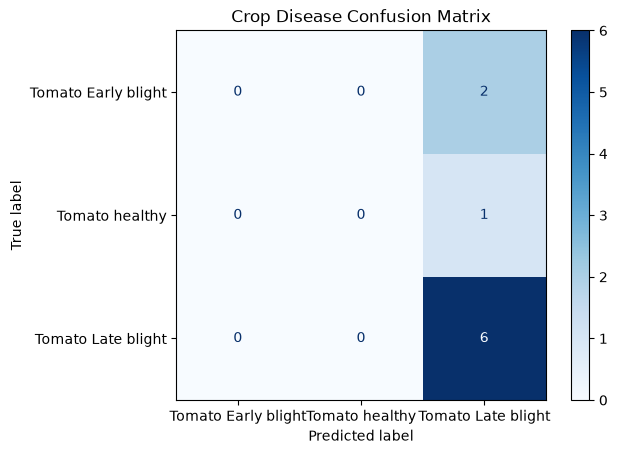

In [100]:
import sklearn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

cm_display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
cm_display.plot(cmap="Blues")
plt.title("Crop Disease Confusion Matrix")
plt.show()

In [113]:
from sklearn.metrics import (accuracy_score,classification_report)

accuracy = accuracy_score(all_labels, all_predictions)
print(f"Model Accuracy: {accuracy:.4}")
print("\nClassification Report:")

print(classification_report(all_labels,all_predictions,target_names=class_names,zero_division=0))

Model Accuracy: 0.6667

Classification Report:
                     precision    recall  f1-score   support

Tomato Early blight       0.00      0.00      0.00         2
     Tomato healthy       0.00      0.00      0.00         1
 Tomato Late blight       0.67      1.00      0.80         6

           accuracy                           0.67         9
          macro avg       0.22      0.33      0.27         9
       weighted avg       0.44      0.67      0.53         9



In [114]:
for actual, predicted in zip(all_labels, all_predictions):

    actual_name = class_names[actual]
    predicted_name = class_names[predicted]

    if actual != predicted:
        print("Actual:   ", actual_name)
        print("Predicted:", predicted_name)
        print("-" * 40)

Actual:    Tomato Early blight
Predicted: Tomato Late blight
----------------------------------------
Actual:    Tomato healthy
Predicted: Tomato Late blight
----------------------------------------
Actual:    Tomato Early blight
Predicted: Tomato Late blight
----------------------------------------


In [115]:
print("Total images:", len(tomato_dataset))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Total images: 9
Training images: 7
Validation images: 2


NameError: name 'test_dataset' is not defined

In [116]:
from collections import Counter

print("All images:", Counter(tomato_dataset.targets))
print("Training:", Counter(train_dataset.dataset.targets[i] for i in train_dataset.indices))
print("Validation:", Counter(val_dataset.dataset.targets[i] for i in val_dataset.indices))

AttributeError: 'TomatoDataset' object has no attribute 'targets'

In [117]:

# Inspect the custom dataset
print("Dataset attributes:")
print(vars(tomato_dataset))

print("\nDataset class:")
print(type(tomato_dataset))

# Inspect one sample
sample_image, sample_label = tomato_dataset[0]

print("\nFirst image shape:", sample_image.shape)
print("First image label:", sample_label)
print("Label type:", type(sample_label))


Dataset attributes:
{'data_dir': WindowsPath('../data/raw'), 'transform': Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
), 'samples': [(WindowsPath('../data/raw/Tomato healthy/image_0001.jpg'), 0), (WindowsPath('../data/raw/Tomato healthy/sample.jpg'), 0), (WindowsPath('../data/raw/Tomato Early blight/sample.jpg'), 1), (WindowsPath('../data/raw/Tomato Late blight/image_0001.jpg'), 2), (WindowsPath('../data/raw/Tomato Late blight/image_0002.jpg'), 2), (WindowsPath('../data/raw/Tomato Late blight/image_0003.jpg'), 2), (WindowsPath('../data/raw/Tomato Late blight/image_0004.jpg'), 2), (WindowsPath('../data/raw/Tomato Late blight/image_0005.jpg'), 2), (WindowsPath('../data/raw/Tomato Late blight/sample.jpg'), 2)]}

Dataset class:
<class '__main__.TomatoDataset'>

First image shape: torch.Size([3, 64, 64])
First image label: 0
Label type: <class 'int'>


In [118]:
from collections import Counter

# Automatically get the correct label-to-class mapping
label_to_class = {
    label: path.parent.name
    for path, label in tomato_dataset.samples
}

class_names = [
    label_to_class[i]
    for i in range(len(label_to_class))
]
print("Correct class order:", class_names)

# Count images in each split
print("\nAll images:", Counter(label for _, label in tomato_dataset.samples))
print("Training:",Counter(tomato_dataset.samples[i][1] for i in train_dataset.indices))
print("Validation:",Counter(tomato_dataset.samples[i][1] for i in val_dataset.indices))

Correct class order: ['Tomato healthy', 'Tomato Early blight', 'Tomato Late blight']

All images: Counter({2: 6, 0: 2, 1: 1})
Training: Counter({2: 6, 0: 1})
Validation: Counter({1: 1, 0: 1})


In [119]:
from pathlib import Path

data_dir = Path("../data/raw")

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))
        print(folder.name, ":", len(images), "images")

Tomato Early blight : 1 images
Tomato healthy : 2 images
Tomato Late blight : 6 images


In [120]:
from datasets import load_dataset
print("Datasets library imported successfully!")

Datasets library imported successfully!


In [122]:
from datasets import load_dataset

dataset = load_dataset("manoela/plantvillage",split="train",streaming=True)
print(dataset)

IterableDataset({
    features: ['image', 'caption', 'captions'],
    num_shards: 1
})


In [ ]:
first_sample = next(iter(dataset))

print(first_sample.keys())
print(first_sample)

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'[Errno 11002] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 2s [Retry 2/5].
'[Errno 11002] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].


In [ ]:
print("Image:", first_sample["image"])
print("Caption:", first_sample["caption"])

In [1]:
import requests

try:
    response = requests.get("https://huggingface.co",timeout=15)
    print("Connection successful:", response.status_code)

except Exception as e:
    print("Connection failed:", e)

Connection failed: HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out.


In [2]:
import requests

try:
    response = requests.get("https://huggingface.co",timeout=60)
    print("Connection successful:", response.status_code)

except Exception as e:
    print("Connection failed:", e)

Connection successful: 200


In [3]:
from datasets import load_dataset

dataset = load_dataset(
    "manoela/plantvillage",
    split="train",
    streaming=True
)

print(dataset)

IterableDataset({
    features: ['image', 'caption', 'captions'],
    num_shards: 1
})


In [7]:
first_sample = next(iter(dataset))

print("Available fields:", first_sample.keys())

print("\nCaption:")
print(first_sample["caption"])

print("\nCaptions:")
print(first_sample["captions"])

print("\nImage type:")
print(type(first_sample["image"]))

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 2s [Retry 2/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'peer closed connection without sending complete message body (received 3971836 bytes, expected 32530561)' t

Available fields: dict_keys(['image', 'caption', 'captions'])

Caption:
Tomato healthy

Captions:
['A vibrant green and healthy tomato leaf with smooth, spotless surface.', 'A healthy Solanum lycopersicum leaf, free of disease or pests, with a uniform green color.', 'A fresh tomato leaf outdoors, glowing in sunlight with a smooth and unblemished surface.', 'A clean and healthy tomato leaf image, perfect for comparison in plant health datasets.']

Image type:
<class 'PIL.JpegImagePlugin.JpegImageFile'>


'peer closed connection without sending complete message body (received 13120635 bytes, expected 32530561)' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'_ssl.c:993: The handshake operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 2s [Retry 2/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/manoela/plantvillage/resolve/12634582388a2780e284f61885973f5c07e29377/data/train-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].
'The read oper

In [6]:
print(first_sample["caption"])

Tomato healthy


In [8]:
from pathlib import Path

data_dir = Path("../data/raw/tomatoplantsplit")

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_dir in sorted((data_dir / split).iterdir()):
        if class_dir.is_dir():
            images = list(class_dir.glob("*"))
            print(class_dir.name, ":", len(images))


TRAIN


FileNotFoundError: [WinError 3] The system cannot find the path specified: '..\\data\\raw\\tomatoplantsplit\\train'

In [9]:
from pathlib import Path

raw_dir = Path("../data/raw")

print("Current notebook location:", Path.cwd())
print("\nFolders inside data/raw:")

for item in raw_dir.iterdir():
    print(item.name)

Current notebook location: C:\Users\pc\CropDiseaseDetection\notebooks

Folders inside data/raw:
Tomato Early blight
Tomato healthy
Tomato Late blight


In [10]:
from pathlib import Path

project_dir = Path.cwd().parent

print("Project folders:")

for item in project_dir.iterdir():
    print(item.name)

Project folders:
app
data
jupyter_runtime
models
notebooks
src
test
train
validation


In [12]:
from pathlib import Path

data_dir = Path.cwd().parent
print("Dataset location:", data_dir)

for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_dir in sorted((data_dir / split).iterdir()):
        if class_dir.is_dir():
            images = [f for f in class_dir.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]]
            print(class_dir.name, ":", len(images))

Dataset location: C:\Users\pc\CropDiseaseDetection

TRAIN
Tomato___Bacterial_spot : 1701
Tomato___healthy : 1272
Tomato___Late_blight : 1527
Tomato___Septoria_leaf_spot : 1416
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 4285

VALIDATION
Tomato___Bacterial_spot : 213
Tomato___healthy : 159
Tomato___Late_blight : 191
Tomato___Septoria_leaf_spot : 177
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 536

TEST
Tomato___Bacterial_spot : 213
Tomato___healthy : 160
Tomato___Late_blight : 191
Tomato___Septoria_leaf_spot : 178
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 536


In [13]:
from torchvision import datasets, transforms
from pathlib import Path

# Main project directory
data_dir = Path.cwd().parent

# Image transformations
transform = transforms.Compose([transforms.Resize((64, 64)),transforms.ToTensor(),transforms.Normalize(mean=(0.5, 0.5, 0.5),std=(0.5, 0.5, 0.5))])

# Load the three datasets
train_dataset = datasets.ImageFolder(data_dir / "train",transform=transform)
val_dataset = datasets.ImageFolder(data_dir / "validation",transform=transform)
test_dataset = datasets.ImageFolder(data_dir / "test",transform=transform)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

print("\nDataset sizes:")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Classes: ['Tomato___Bacterial_spot', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']
Class mapping: {'Tomato___Bacterial_spot': 0, 'Tomato___Late_blight': 1, 'Tomato___Septoria_leaf_spot': 2, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 3, 'Tomato___healthy': 4}

Dataset sizes:
Training: 10201
Validation: 1276
Testing: 1278


In [14]:
from torch.utils.data import DataLoader

# Batch size
BATCH_SIZE = 32

# Create DataLoaders
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_loader = DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 319
Validation batches: 40
Testing batches: 40


In [15]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("First 10 labels:", labels[:10])

Images shape: torch.Size([32, 3, 64, 64])
Labels shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
First 10 labels: tensor([3, 4, 2, 2, 3, 0, 3, 3, 3, 1])


In [16]:
import torch
import torch.nn as nn

class TomatoCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),nn.ReLU(),nn.MaxPool2d(2))

        self.classifier = nn.Sequential(nn.Flatten(),nn.Linear(64 * 8 * 8, 128),nn.ReLU(),nn.Dropout(0.5),nn.Linear(128, 5))

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = TomatoCNN()

print(model)

TomatoCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)


In [17]:
# Get one batch
images, labels = next(iter(train_loader))

# Pass images through CNN
outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 64, 64])
Output shape: torch.Size([32, 5])


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to device
model = model.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(),lr=0.001)

print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer)


Device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [19]:
import os

# Number of training epochs
EPOCHS = 10

# Store training history
history = {"train_loss": [],"train_accuracy": [],"val_loss": [],"val_accuracy": []}

# Create models directory if it doesn't exist
os.makedirs(data_dir / "models", exist_ok=True)

best_val_accuracy = 0.0

for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        train_loss += loss.item()

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100 * train_correct / train_total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # Record history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(),data_dir / "models" / "best_model.pth")

    print(f"Epoch [{epoch+1}/{EPOCHS}] "f"Train Loss: {train_loss:.4f} "f"Train Acc: {train_accuracy:.2f}% "f"Val Loss: {val_loss:.4f} "f"Val Acc: {val_accuracy:.2f}%")

print("\nBest Validation Accuracy:", best_val_accuracy)

Epoch [1/10] Train Loss: 0.6244 Train Acc: 76.29% Val Loss: 0.3034 Val Acc: 88.79%
Epoch [2/10] Train Loss: 0.3148 Train Acc: 89.15% Val Loss: 0.2243 Val Acc: 91.85%
Epoch [3/10] Train Loss: 0.2141 Train Acc: 93.08% Val Loss: 0.1553 Val Acc: 93.89%
Epoch [4/10] Train Loss: 0.1606 Train Acc: 94.63% Val Loss: 0.1669 Val Acc: 93.34%
Epoch [5/10] Train Loss: 0.1471 Train Acc: 95.00% Val Loss: 0.2261 Val Acc: 92.16%
Epoch [6/10] Train Loss: 0.1188 Train Acc: 96.14% Val Loss: 0.0931 Val Acc: 96.47%
Epoch [7/10] Train Loss: 0.1077 Train Acc: 96.71% Val Loss: 0.0815 Val Acc: 97.41%
Epoch [8/10] Train Loss: 0.0878 Train Acc: 96.82% Val Loss: 0.0656 Val Acc: 98.12%
Epoch [9/10] Train Loss: 0.0760 Train Acc: 97.49% Val Loss: 0.0709 Val Acc: 98.20%
Epoch [10/10] Train Loss: 0.0645 Train Acc: 97.86% Val Loss: 0.1009 Val Acc: 96.63%

Best Validation Accuracy: 98.1974921630094


In [20]:
# Load the best validation checkpoint
model.load_state_dict(torch.load(data_dir / "models" / "best_model.pth", map_location=device))
model.eval()
print("Best model loaded successfully!")

Best model loaded successfully!


Test Accuracy: 97.97%

Classification Report:
                                        precision    recall  f1-score   support

               Tomato___Bacterial_spot       1.00      0.95      0.97       213
                  Tomato___Late_blight       0.94      0.96      0.95       191
           Tomato___Septoria_leaf_spot       0.98      0.98      0.98       178
Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      0.99      0.99       536
                      Tomato___healthy       0.98      1.00      0.99       160

                              accuracy                           0.98      1278
                             macro avg       0.98      0.98      0.98      1278
                          weighted avg       0.98      0.98      0.98      1278



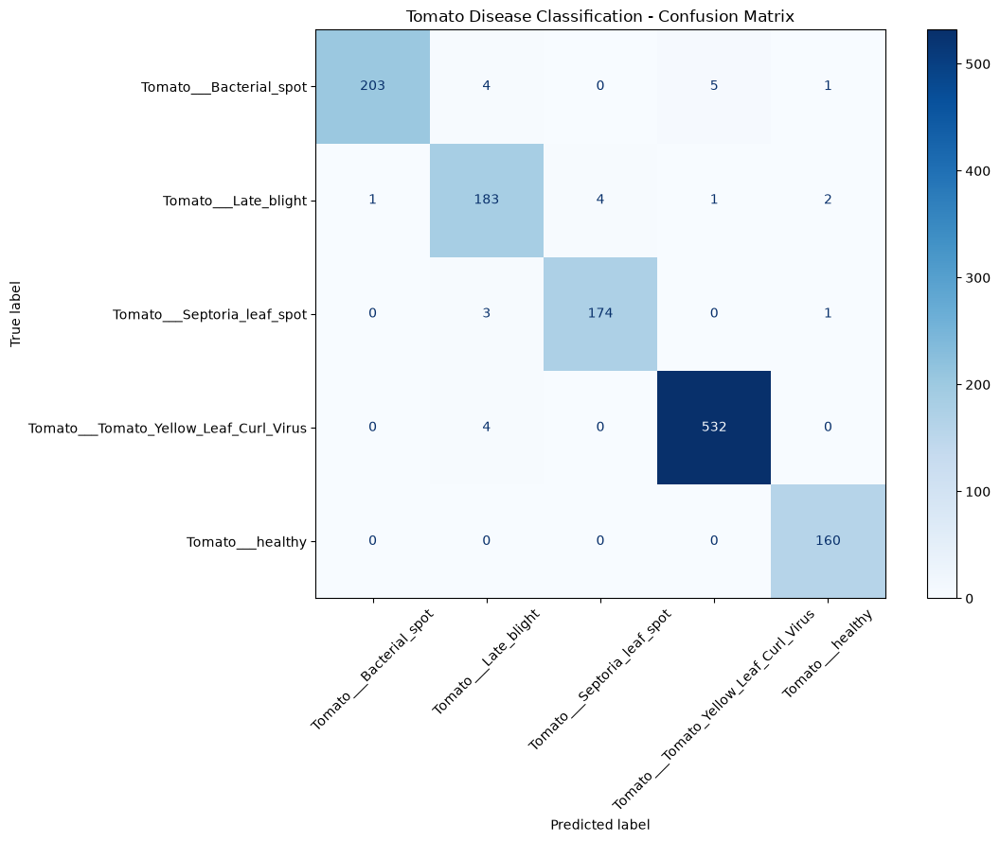

In [21]:
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

import matplotlib.pyplot as plt

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Overall accuracy
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_true,y_pred,target_names=test_dataset.classes,zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=test_dataset.classes)

fig, ax = plt.subplots(figsize=(12, 9))
display.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("Tomato Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
# Get the paths of all test images
test_paths = [sample[0] for sample in test_dataset.samples]

# Store misclassified images
errors = []

for i in range(len(y_true)):
    if y_true[i] != y_pred[i]:
        errors.append({"image": test_paths[i],"actual": test_dataset.classes[y_true[i]],"predicted": test_dataset.classes[y_pred[i]]})

print("Total errors:", len(errors))

for error in errors[:10]:
    print("\nImage:", error["image"])
    print("Actual:", error["actual"])
    print("Predicted:", error["predicted"])

Total errors: 26

Image: C:\Users\pc\CropDiseaseDetection\test\Tomato___Bacterial_spot\06d99389-13fd-4fd1-8734-eb82ea657ce3___UF.GRC_BS_Lab Leaf 8896.JPG
Actual: Tomato___Bacterial_spot
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus

Image: C:\Users\pc\CropDiseaseDetection\test\Tomato___Bacterial_spot\13affc42-3a89-4a99-97aa-98f41682a71e___UF.GRC_BS_Lab Leaf 0546.JPG
Actual: Tomato___Bacterial_spot
Predicted: Tomato___Late_blight

Image: C:\Users\pc\CropDiseaseDetection\test\Tomato___Bacterial_spot\8897f549-538f-46d9-a2f7-53eb07e7f89d___UF.GRC_BS_Lab Leaf 8885.JPG
Actual: Tomato___Bacterial_spot
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus

Image: C:\Users\pc\CropDiseaseDetection\test\Tomato___Bacterial_spot\942627c0-ec98-4b60-8e2e-520166b51d5e___UF.GRC_BS_Lab Leaf 0492.JPG
Actual: Tomato___Bacterial_spot
Predicted: Tomato___Late_blight

Image: C:\Users\pc\CropDiseaseDetection\test\Tomato___Bacterial_spot\9b1443e6-25d0-4dbb-a3f4-b586d7cce49f___UF.GRC_BS_Lab Leaf 8769.JPG
Actual

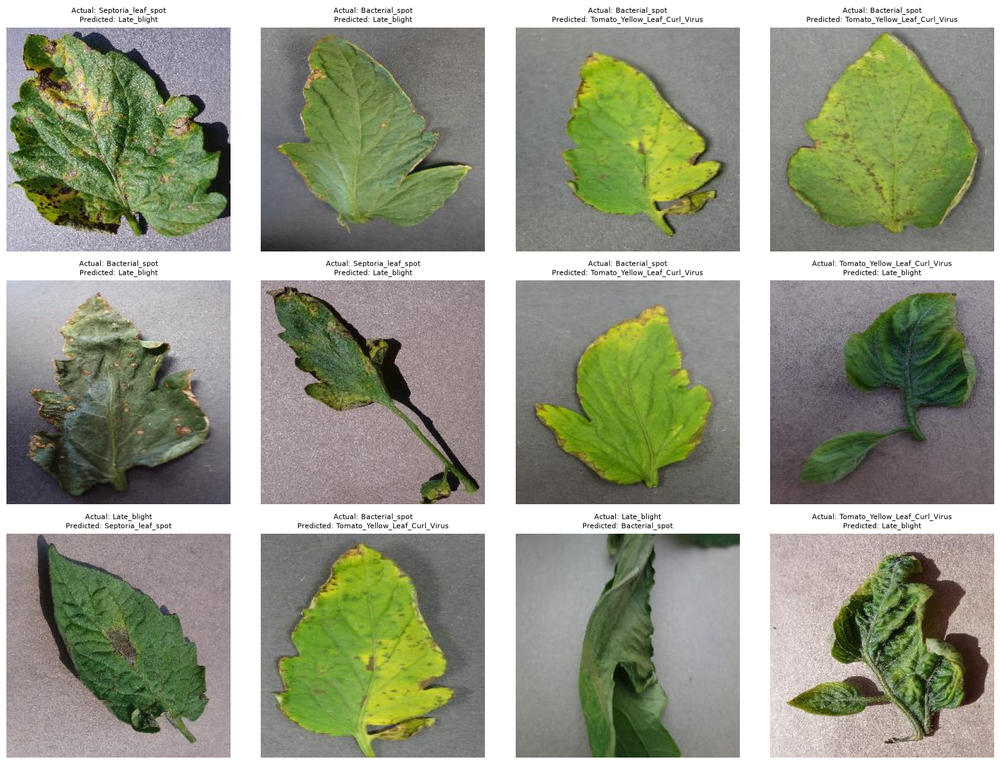

In [23]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Select up to 12 errors from different positions in the list
sample_errors = random.Random(42).sample(errors, min(12, len(errors)))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, error in zip(axes, sample_errors):
    img = Image.open(error["image"]).convert("RGB")

    ax.imshow(img)
    ax.set_title(f"Actual: {error['actual'].replace('Tomato___', '')}\n"f"Predicted: {error['predicted'].replace('Tomato___', '')}",fontsize=8)
    ax.axis("off")

# Hide unused axes
for ax in axes[len(sample_errors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
from collections import Counter

error_pairs = Counter()

for error in errors:
    pair = (error["actual"], error["predicted"])
    error_pairs[pair] += 1

for (actual, predicted), count in error_pairs.most_common():
    print(f"{actual} -> {predicted}: {count}")

Tomato___Bacterial_spot -> Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5
Tomato___Bacterial_spot -> Tomato___Late_blight: 4
Tomato___Late_blight -> Tomato___Septoria_leaf_spot: 4
Tomato___Tomato_Yellow_Leaf_Curl_Virus -> Tomato___Late_blight: 4
Tomato___Septoria_leaf_spot -> Tomato___Late_blight: 3
Tomato___Late_blight -> Tomato___healthy: 2
Tomato___Bacterial_spot -> Tomato___healthy: 1
Tomato___Late_blight -> Tomato___Tomato_Yellow_Leaf_Curl_Virus: 1
Tomato___Late_blight -> Tomato___Bacterial_spot: 1
Tomato___Septoria_leaf_spot -> Tomato___healthy: 1


In [25]:
import hashlib
from pathlib import Path
from collections import defaultdict

splits = ["train", "validation", "test"]

image_hashes = defaultdict(list)

for split in splits:
    split_dir = data_dir / split

    for image_path in split_dir.rglob("*"):
        if image_path.is_file():
            try:
                with open(image_path, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                image_hashes[file_hash].append((split, str(image_path)))

            except Exception:
                pass

duplicates = {
    h: paths
    for h, paths in image_hashes.items()
    if len({split for split, path in paths}) > 1
}

print("Cross-split duplicate groups:", len(duplicates))

for paths in list(duplicates.values())[:10]:
    print("\n")
    for split, path in paths:
        print(split, ":", path)

Cross-split duplicate groups: 4


train : C:\Users\pc\CropDiseaseDetection\train\Tomato___healthy\d2ce7896-6fa4-45e6-96c5-d162da0e3e1c___GH_HL Leaf 220.JPG
test : C:\Users\pc\CropDiseaseDetection\test\Tomato___healthy\9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG


train : C:\Users\pc\CropDiseaseDetection\train\Tomato___Late_blight\2c47b891-3c97-48f1-a2cc-5aa53d3a1148___GHLB2 Leaf 9011.JPG
validation : C:\Users\pc\CropDiseaseDetection\validation\Tomato___Late_blight\1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG


train : C:\Users\pc\CropDiseaseDetection\train\Tomato___Late_blight\5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg
test : C:\Users\pc\CropDiseaseDetection\test\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg


train : C:\Users\pc\CropDiseaseDetection\train\Tomato___Late_blight\c1775bad-7c02-41fb-bb7d-f8df91d60ac3___GHLB_PS Leaf 23.5 Day 13.jpg
validation : C:\Users\pc\CropDiseaseDetection\valida

In [26]:
from pathlib import Path

for paths in duplicates.values():
    for split, path in paths:
        if split != "train":
            source = Path(path)

            relative_path = source.relative_to(data_dir / split)
            destination = ( data_dir / "quarantine" / split / relative_path )

            print("FROM:", source)
            print("TO:  ", destination)
            print()

FROM: C:\Users\pc\CropDiseaseDetection\test\Tomato___healthy\9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG
TO:   C:\Users\pc\CropDiseaseDetection\quarantine\test\Tomato___healthy\9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG

FROM: C:\Users\pc\CropDiseaseDetection\validation\Tomato___Late_blight\1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG
TO:   C:\Users\pc\CropDiseaseDetection\quarantine\validation\Tomato___Late_blight\1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG

FROM: C:\Users\pc\CropDiseaseDetection\test\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg
TO:   C:\Users\pc\CropDiseaseDetection\quarantine\test\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg

FROM: C:\Users\pc\CropDiseaseDetection\validation\Tomato___Late_blight\98586693-fe1f-4ea0-8e27-4501b61cf09b___GHLB_PS Leaf 23.5 Day 13.jpg
TO:   C:\Users\pc\CropDiseaseDetection\quarantine\validation\Toma

In [27]:
import shutil

moved_count = 0

for paths in duplicates.values():
    for split, path in paths:
        if split != "train":
            source = Path(path)

            relative_path = source.relative_to( data_dir / split)

            destination = (data_dir / "quarantine" / split / relative_path)

            # Create the destination folder
            destination.parent.mkdir(parents=True,exist_ok=True)

            # Move the duplicate file
            shutil.move(str(source), str(destination))

            moved_count += 1

print("Files moved:", moved_count)

Files moved: 4


In [28]:
image_hashes = defaultdict(list)

for split in splits:
    split_dir = data_dir / split

    for image_path in split_dir.rglob("*"):
        if image_path.is_file():
            try:
                with open(image_path, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                image_hashes[file_hash].append((split, str(image_path)))

            except Exception:
                pass

duplicates = {
    h: paths
    for h, paths in image_hashes.items()
    if len({split for split, path in paths}) > 1
}

print("Cross-split duplicate groups:", len(duplicates))

for paths in list(duplicates.values())[:10]:
    print("\n")
    for split, path in paths:
        print(split, ":", path)

Cross-split duplicate groups: 0


In [29]:
train_dataset = datasets.ImageFolder(data_dir / "train",transform=transform)
val_dataset = datasets.ImageFolder(data_dir / "validation",transform=transform)
test_dataset = datasets.ImageFolder(data_dir / "test",transform=transform)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 10201
Validation images: 1274
Test images: 1276


In [30]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [31]:
# Create a fresh model
model = TomatoCNN().to(device)

# Define a fresh loss function
criterion = nn.CrossEntropyLoss()

# Create a new optimizer
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

# Reset training history
history = {"train_loss": [],"train_accuracy": [],"val_loss": [],"val_accuracy": []}

# Reset best validation accuracy
best_val_accuracy = 0.0

EPOCHS = 10

print("Fresh model ready!")

Fresh model ready!


In [32]:
import os

# Number of training epochs
EPOCHS = 10

# Store training history
history = {"train_loss": [],"train_accuracy": [],"val_loss": [],"val_accuracy": []}

# Create models directory if it doesn't exist
os.makedirs(data_dir / "models", exist_ok=True)

best_val_accuracy = 0.0

for epoch in range(EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        train_loss += loss.item()

        # Get predicted classes
        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100 * train_correct / train_total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    # Record history
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(),data_dir / "models" / "best_model.pth")

    print(f"Epoch [{epoch+1}/{EPOCHS}] "f"Train Loss: {train_loss:.4f} "f"Train Acc: {train_accuracy:.2f}% "f"Val Loss: {val_loss:.4f} "f"Val Acc: {val_accuracy:.2f}%")

print("\nBest Validation Accuracy:", best_val_accuracy)

Epoch [1/10] Train Loss: 0.6346 Train Acc: 76.34% Val Loss: 0.3345 Val Acc: 86.58%
Epoch [2/10] Train Loss: 0.3223 Train Acc: 88.60% Val Loss: 0.2051 Val Acc: 92.70%
Epoch [3/10] Train Loss: 0.2463 Train Acc: 91.26% Val Loss: 0.1604 Val Acc: 94.11%
Epoch [4/10] Train Loss: 0.2098 Train Acc: 92.65% Val Loss: 0.2078 Val Acc: 91.37%
Epoch [5/10] Train Loss: 0.1541 Train Acc: 94.96% Val Loss: 0.1112 Val Acc: 95.05%
Epoch [6/10] Train Loss: 0.1499 Train Acc: 94.96% Val Loss: 0.1007 Val Acc: 96.08%
Epoch [7/10] Train Loss: 0.1103 Train Acc: 96.44% Val Loss: 0.0825 Val Acc: 97.10%
Epoch [8/10] Train Loss: 0.1059 Train Acc: 96.44% Val Loss: 0.1272 Val Acc: 95.76%
Epoch [9/10] Train Loss: 0.0938 Train Acc: 96.80% Val Loss: 0.0696 Val Acc: 97.80%
Epoch [10/10] Train Loss: 0.0864 Train Acc: 97.07% Val Loss: 0.0756 Val Acc: 97.17%

Best Validation Accuracy: 97.8021978021978


In [33]:
model.load_state_dict(torch.load(data_dir / "models" / "best_model.pth",map_location=device))

model.eval()

TomatoCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)

Test Accuracy: 98.20%

Classification Report:
                                        precision    recall  f1-score   support

               Tomato___Bacterial_spot       0.97      0.98      0.97       213
                  Tomato___Late_blight       0.97      0.96      0.97       190
           Tomato___Septoria_leaf_spot       0.96      0.98      0.97       178
Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      0.99      0.99       536
                      Tomato___healthy       1.00      0.99      0.99       159

                              accuracy                           0.98      1276
                             macro avg       0.98      0.98      0.98      1276
                          weighted avg       0.98      0.98      0.98      1276



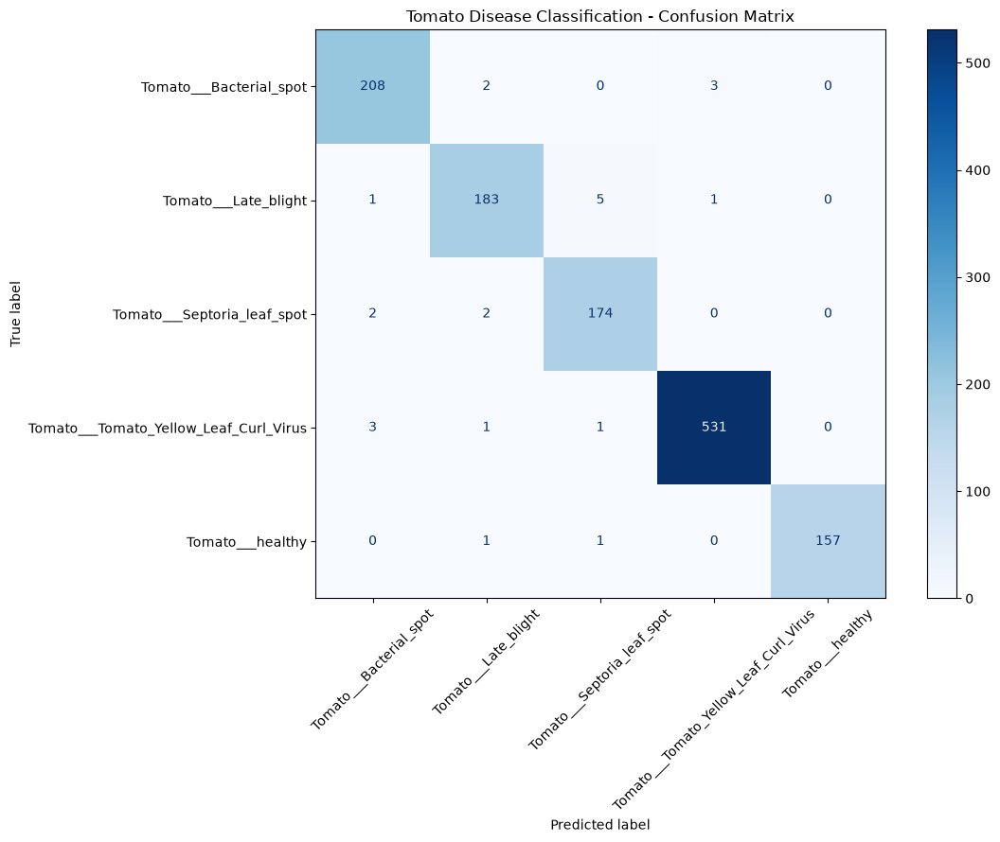

In [34]:
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

import matplotlib.pyplot as plt

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Overall accuracy
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_true,y_pred,target_names=test_dataset.classes,zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=test_dataset.classes)

fig, ax = plt.subplots(figsize=(12, 9))
display.plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.title("Tomato Disease Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [35]:
checkpoint_path = data_dir / "models" / "best_model.pth"

model.load_state_dict(torch.load(checkpoint_path, map_location=device))

model.eval()

TomatoCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=5, bias=True)
  )
)

In [36]:
checkpoint = {"model_state_dict": model.state_dict(),"class_names": train_dataset.classes,"class_to_idx": train_dataset.class_to_idx,"image_size": 64,"mean": [0.5, 0.5, 0.5],"std": [0.5, 0.5, 0.5]}

torch.save(checkpoint,data_dir / "models" / "tomato_cnn_final.pth")

In [37]:
from torchvision import transforms

prediction_transform = transforms.Compose([transforms.Resize((64, 64)),transforms.ToTensor(),transforms.Normalize(mean=(0.5, 0.5, 0.5),std=(0.5, 0.5, 0.5))])

In [38]:
from PIL import Image
import torch

def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")
    image_tensor = prediction_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, dim=1)
        
    predicted_class = train_dataset.classes[predicted_idx.item()]

    return predicted_class, confidence.item()

In [39]:
sample_path = test_dataset.samples[0][0]

predicted_class, confidence = predict_image(sample_path)

print("Predicted disease:", predicted_class)
print("Confidence:", f"{confidence:.2%}")

Predicted disease: Tomato___Bacterial_spot
Confidence: 99.70%


In [40]:
image_path, actual_label = test_dataset.samples[0]

predicted_class, confidence = predict_image(image_path)

print("Actual disease:", test_dataset.classes[actual_label])
print("Predicted disease:", predicted_class)
print("Confidence:", f"{confidence:.2%}")

Actual disease: Tomato___Bacterial_spot
Predicted disease: Tomato___Bacterial_spot
Confidence: 99.70%


In [42]:
%pip install gradio

   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/31.4 MB ? eta -:--:--
    --------------------------------------- 0.5/31.4 MB 270.5 kB/s eta 0:01:55
    --------------------------------------- 0.5/31.4 MB 270.5 kB/s eta 0:01:55
    --------------------------------------- 0.5/31.4 MB 270.5 kB/s eta 0:01:55
    --------------------------------------- 0.5/31.4 MB 270.5 kB/s eta 0:01:55
   - -------------------------------------- 0.8/31.4 M

In [43]:
import gradio as gr
print(gr.__version__)

6.31.0


In [44]:
import gradio as gr
import torch
import torch.nn as nn
from torchvision import transforms

In [50]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

print(BASE_DIR)

C:\Users\pc\CropDiseaseDetection


In [48]:
print("Project directory:", BASE_DIR)
print("Model directory:", BASE_DIR / "models")
print("Model exists:", (BASE_DIR / "models" / "tomato_cnn_final.pth").exists())

Project directory: C:\Users\pc\CropDiseaseDetection
Model directory: C:\Users\pc\CropDiseaseDetection\models
Model exists: True


In [45]:
class TomatoCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [57]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

checkpoint_path = BASE_DIR / "models" / "tomato_cnn_final.pth"

checkpoint = torch.load(checkpoint_path, map_location=device)

model = TomatoCNN().to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

class_names = checkpoint["class_names"]

In [58]:
print("Model loaded successfully!")
print("Classes:", class_names)
print("Device:", device)

Model loaded successfully!
Classes: ['Tomato___Bacterial_spot', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']
Device: cpu


In [59]:
def predict_image(image):
    if image is None:
        return {}

    image = image.convert("RGB")

    image_tensor = prediction_transform(image)
    image_tensor = image_tensor.unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)[0]

    results = {
        class_names[i]: float(probabilities[i])
        for i in range(len(class_names))
    }

    return results

In [61]:
demo = gr.Interface(fn=predict_image,inputs=gr.Image(type="pil"),outputs=gr.Label(num_top_classes=5),title="Tomato Leaf Disease Detection",description="Upload a tomato leaf image to identify its disease.")
demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [62]:
from PIL import Image

image_path = r"C:\path\to\your\downloaded_image.jpg"

image = Image.open(image_path)

predictions = predict_image(image)

for disease, probability in predictions.items():
    print(f"{disease}: {probability:.8f} ({probability * 100:.5f}%)")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\path\\to\\your\\downloaded_image.jpg'

In [63]:
from pathlib import Path

downloads = Path.home() / "Downloads"

print("Downloads folder:", downloads)

for file in downloads.iterdir():
    if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
        print(file)

Downloads folder: C:\Users\pc\Downloads
C:\Users\pc\Downloads\BirdPhoto.jpg
C:\Users\pc\Downloads\ChatGPT Image Oct 12, 2026, 10_30_45 AM (1).png
C:\Users\pc\Downloads\ChatGPT Image Oct 12, 2026, 10_30_46 AM (2).png
C:\Users\pc\Downloads\ChatGPT Image Oct 8, 2026, 11_55_57 AM.png
C:\Users\pc\Downloads\ChatGPT Image Oct 8, 2026, 11_58_50 AM.png
C:\Users\pc\Downloads\ChatGPT Image Oct 8, 2026, 12_03_09 PM.png
C:\Users\pc\Downloads\converted_image.jpg
C:\Users\pc\Downloads\dylan-fout-YA1JFNB67lQ-unsplash.jpg
C:\Users\pc\Downloads\Flowers.jpg
C:\Users\pc\Downloads\generated_image_0.png
C:\Users\pc\Downloads\generated_image_1.png
C:\Users\pc\Downloads\generated_image_2.png
C:\Users\pc\Downloads\generated_image_3.png
C:\Users\pc\Downloads\istockphoto-2215964712-1024x1024.jpg
C:\Users\pc\Downloads\muru'ah.jpeg
C:\Users\pc\Downloads\saved-image-file_000000001ce081f49665df45aafc1325.jpg
C:\Users\pc\Downloads\saved-image-file_000000002ddc8210aa173668865b5d89.jpg
C:\Users\pc\Downloads\saved-image

In [65]:
image_path = downloads / "YOUR_IMAGE_FILENAME.jpg"

image = Image.open(image_path).convert("RGB")

predictions = predict_image(image)

for disease, probability in predictions.items():
    print(f"{disease}: {probability * 100:.6f}%")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\pc\\Downloads\\YOUR_IMAGE_FILENAME.jpg'

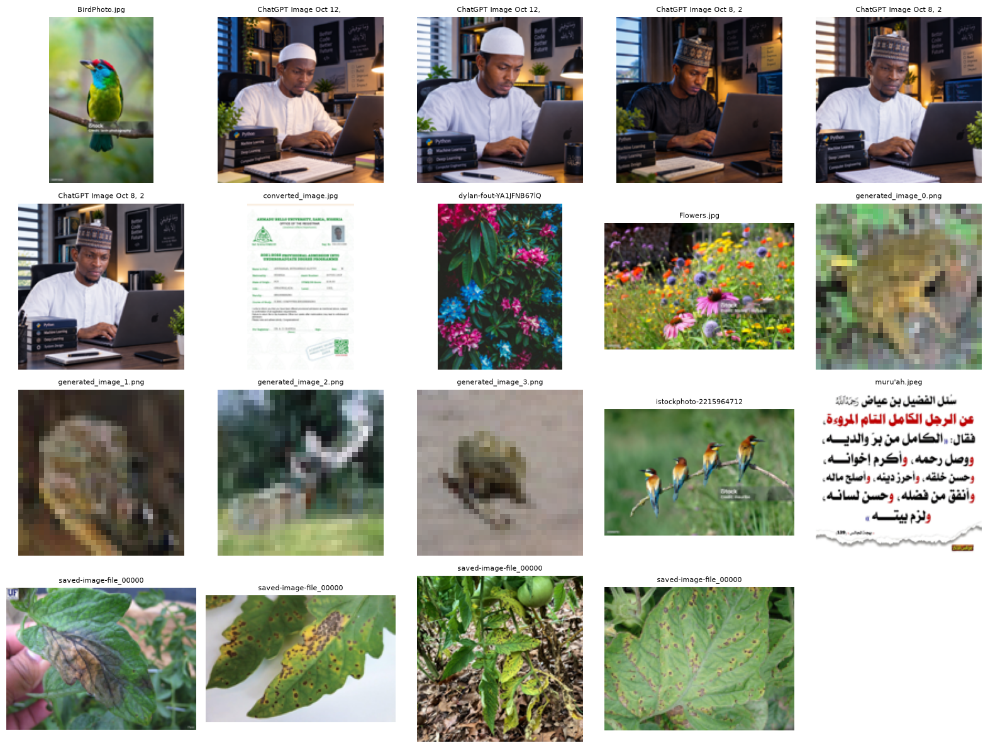

In [66]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

image_files = [
    f for f in downloads.iterdir()
    if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

fig, axes = plt.subplots(4, 5, figsize=(16, 12))
axes = axes.flatten()

for ax, file in zip(axes, image_files):
    img = Image.open(file).convert("RGB")
    img.thumbnail((150, 150))

    ax.imshow(img)
    ax.set_title(file.name[:22], fontsize=8)
    ax.axis("off")

for ax in axes[len(image_files):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [67]:
image_path = downloads / "istockphoto-2215964712-1024x1024.jpg"
image = Image.open(image_path).convert("RGB")

predictions = predict_image(image)

for disease, probability in predictions.items():
    print(f"{disease}: {probability * 100:.6f}%")

Tomato___Bacterial_spot: 0.020572%
Tomato___Late_blight: 99.937868%
Tomato___Septoria_leaf_spot: 0.003264%
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 0.038264%
Tomato___healthy: 0.000019%


In [68]:
bird_path = downloads / "BirdPhoto.jpg"

bird_image = Image.open(bird_path).convert("RGB")

bird_predictions = predict_image(bird_image)

for disease, probability in bird_predictions.items():
    print(f"{disease}: {probability * 100:.6f}%")

Tomato___Bacterial_spot: 0.000000%
Tomato___Late_blight: 0.005597%
Tomato___Septoria_leaf_spot: 0.000000%
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 99.994397%
Tomato___healthy: 0.000000%


In [70]:
if image is None:
    return {}
image = image.convert("RGB")

SyntaxError: 'return' outside function (3038341818.py, line 2)

In [71]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

for split in ["train", "validation", "test"]:
    folder = BASE_DIR / split

    print(f"\n{split.upper()}")

    for class_folder in folder.iterdir():
        if class_folder.is_dir():
            count = len(list(class_folder.glob("*")))
            print(class_folder.name, ":", count)


TRAIN
Tomato___Bacterial_spot : 1701
Tomato___healthy : 1272
Tomato___Late_blight : 1527
Tomato___Septoria_leaf_spot : 1416
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 4285

VALIDATION
Tomato___Bacterial_spot : 213
Tomato___healthy : 159
Tomato___Late_blight : 189
Tomato___Septoria_leaf_spot : 177
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 536

TEST
Tomato___Bacterial_spot : 213
Tomato___healthy : 159
Tomato___Late_blight : 190
Tomato___Septoria_leaf_spot : 178
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 536


In [72]:
from torchvision.datasets import CIFAR10
from pathlib import Path

BASE_DIR = Path.cwd().parent

external_dir = BASE_DIR / "data" / "external"
external_dir.mkdir(parents=True, exist_ok=True)

cifar_train = CIFAR10(
    root=str(external_dir),
    train=True,
    download=True
)

cifar_test = CIFAR10(
    root=str(external_dir),
    train=False,
    download=True
)

print("Training images:", len(cifar_train))
print("Test images:", len(cifar_test))
print("Classes:", cifar_train.classes)

100%|██████████| 170M/170M [28:08<00:00, 101kB/s]    


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


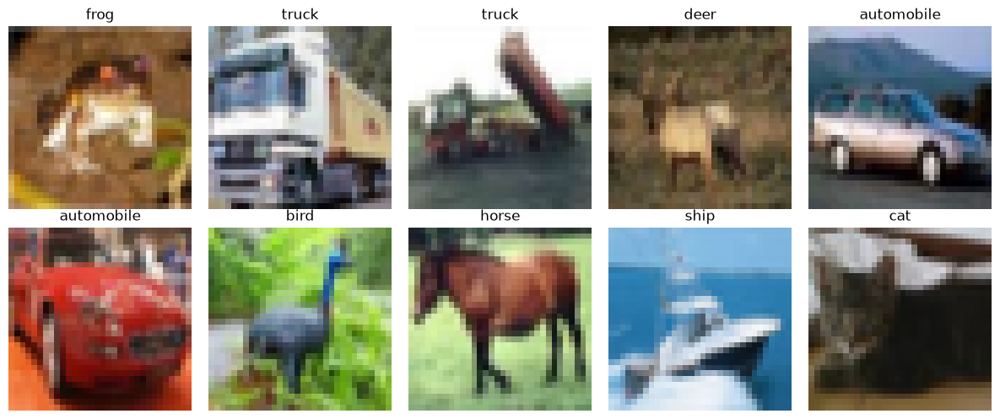

In [74]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = cifar_train[i]

    ax.imshow(image)
    ax.set_title(cifar_train.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [75]:
from collections import Counter

print("Training distribution:")
print(Counter(cifar_train.targets))

print("\nTest distribution:")
print(Counter(cifar_test.targets))

Training distribution:
Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})

Test distribution:
Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})


In [77]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

negative_dir = BASE_DIR / "data" / "external" / "negative_images"

for split in ["train", "test"]:
    for class_name in cifar_train.classes:
        folder = negative_dir / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Negative-image folders created successfully!")
print(list((negative_dir / "train").iterdir()))

Negative-image folders created successfully!
[WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/airplane'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/automobile'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/bird'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/cat'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/deer'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/dog'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/frog'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/horse'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/ship'), WindowsPath('C:/Users/pc/CropDiseaseDetection/data/external/negative_images/train/truck')]


In [78]:
from collections import defaultdict

# Track how many images we save per class
train_counts = defaultdict(int)
test_counts = defaultdict(int)

# Save 200 training images per class
for image, label in cifar_train:
    class_name = cifar_train.classes[label]

    if train_counts[class_name] < 200:
        folder = negative_dir / "train" / class_name
        image.save(folder / f"{train_counts[class_name]}.jpg")
        train_counts[class_name] += 1

    if all(count == 200 for count in train_counts.values()) and len(train_counts) == 10:
        break

# Save 50 test images per class
for image, label in cifar_test:
    class_name = cifar_test.classes[label]

    if test_counts[class_name] < 50:
        folder = negative_dir / "test" / class_name
        image.save(folder / f"{test_counts[class_name]}.jpg")
        test_counts[class_name] += 1

    if all(count == 50 for count in test_counts.values()) and len(test_counts) == 10:
        break

print("Training images:", sum(train_counts.values()))
print("Test images:", sum(test_counts.values()))
print("Training distribution:", dict(train_counts))
print("Test distribution:", dict(test_counts))

Training images: 2000
Test images: 500
Training distribution: {'frog': 200, 'truck': 200, 'deer': 200, 'automobile': 200, 'bird': 200, 'horse': 200, 'ship': 200, 'cat': 200, 'dog': 200, 'airplane': 200}
Test distribution: {'cat': 50, 'ship': 50, 'airplane': 50, 'frog': 50, 'automobile': 50, 'truck': 50, 'dog': 50, 'horse': 50, 'deer': 50, 'bird': 50}


In [79]:
for split in ["train", "test"]:
    print(f"\n{split.upper()}")

    for class_name in cifar_train.classes:
        folder = negative_dir / split / class_name
        images = list(folder.glob("*.jpg"))

        print(f"{class_name}: {len(images)}")


TRAIN
airplane: 200
automobile: 200
bird: 200
cat: 200
deer: 200
dog: 200
frog: 200
horse: 200
ship: 200
truck: 200

TEST
airplane: 50
automobile: 50
bird: 50
cat: 50
deer: 50
dog: 50
frog: 50
horse: 50
ship: 50
truck: 50


In [80]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [81]:
import datasets

print("Datasets version:", datasets.__version__)

Datasets version: 5.1.0


In [82]:
from datasets import load_dataset_builder

dataset_id = "Gunjan12r/plant-disease-detection"

builder = load_dataset_builder(dataset_id)

print("Dataset features:")
print(builder.info.features)

print("\nDataset splits:")
print(builder.info.splits)

README.md:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

C:\Users\pc\miniconda3\envs\deeplearning\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\datasets--Gunjan12r--plant-disease-detection. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Dataset features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy'])}

Dataset splits:
{'train': SplitInfo(name='train', num_bytes=452977044, num_examples=28580), 'validation': SplitInfo(name='validation', num_bytes=56058616, num_examples=3572), 'test': SplitInfo(name='test', num_bytes=55095505, num_examples=3573)}


In [83]:
from datasets import load_dataset

plant_stream = load_dataset(dataset_id,split="train",streaming=True)

sample = next(iter(plant_stream))

print("Label:", sample["label"])
print("Class:", builder.info.features["label"].names[sample["label"]])
print("Image type:", type(sample["image"]))
print("Image size:", sample["image"].size)

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/Gunjan12r/plant-disease-detection/resolve/913258768f93535c74a60d7bf270972041af4f9d/data/train-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/Gunjan12r/plant-disease-detection/resolve/913258768f93535c74a60d7bf270972041af4f9d/data/train-00000-of-00001.parquet
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/Gunjan12r/plant-disease-detection/resolve/913258768f93535c74a60d7bf270972041af4f9d/data/train-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/Gunjan12r/plant-disease-detection/resolve/913258768f93535c74a60d7bf270972041af4f9d/data/train-00000-of-00001.parquet
Retrying in 8s [Retry 4/5].
'[Errno 11001] getaddrinfo failed' thrown wh

Label: 7
Class: Corn_(maize)___healthy
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (256, 256)


In [84]:
negative_classes = [
    name for name in builder.info.features["label"].names
    if not name.startswith("Tomato")
]

print("Negative classes:", len(negative_classes))

for name in negative_classes:
    print(name)

Negative classes: 13
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy


In [85]:
from collections import Counter

negative_class_counts = Counter()
MAX_PER_CLASS = 100

print("Target classes:", len(negative_classes))
print("Target images:", len(negative_classes) * MAX_PER_CLASS)

Target classes: 13
Target images: 1300


In [86]:
plant_negative_dir = (BASE_DIR / "data" / "external" / "PlantDisease" / "train")

for class_name in negative_classes:
    (plant_negative_dir / class_name).mkdir(parents=True,exist_ok=True)

print("Created folders:", len(negative_classes))

Created folders: 13


In [88]:
from collections import Counter

plant_counts = Counter()

plant_stream = load_dataset(dataset_id,split="train",streaming=True)

for sample in plant_stream:

    class_name = builder.info.features["label"].names[sample["label"]]

    # Skip tomato images
    if class_name.startswith("Tomato"):
        continue

    # Stop collecting from a class once it reaches 100
    if plant_counts[class_name] >= MAX_PER_CLASS:
        continue

    image = sample["image"].convert("RGB")

    save_path = (plant_negative_dir/ class_name/ f"{plant_counts[class_name]}.jpg")

    image.save(save_path, format="JPEG")
    plant_counts[class_name] += 1

    # Stop when all 13 classes reach 100
    if len(plant_counts) == len(negative_classes) and all(
        plant_counts[name] == MAX_PER_CLASS
        for name in negative_classes
    ):
        break

print("Total images:", sum(plant_counts.values()))
print("Class distribution:", dict(plant_counts))

Total images: 1300
Class distribution: {'Corn_(maize)___healthy': 100, 'Apple___Cedar_apple_rust': 100, 'Potato___Late_blight': 100, 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 100, 'Corn_(maize)___Common_rust_': 100, 'Apple___healthy': 100, 'Potato___Early_blight': 100, 'Apple___Apple_scab': 100, 'Pepper__bell___healthy': 100, 'Pepper__bell___Bacterial_spot': 100, 'Corn_(maize)___Northern_Leaf_Blight': 100, 'Apple___Black_rot': 100, 'Potato___healthy': 100}


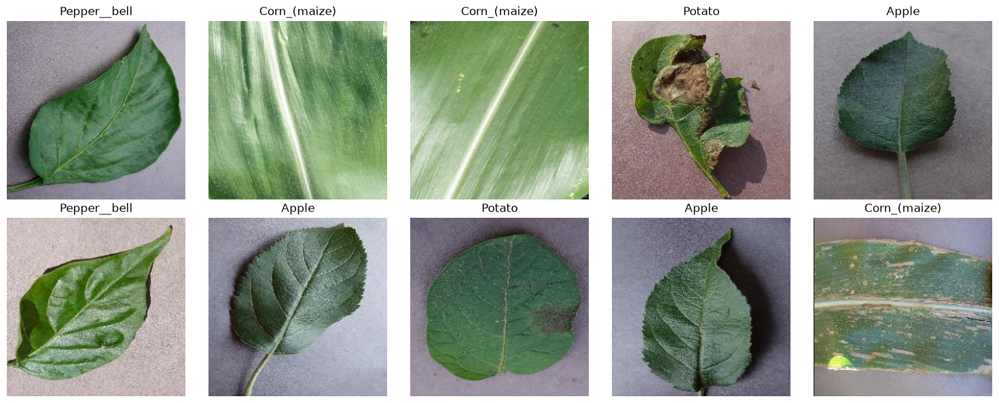

In [89]:
import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax in axes.flat:
    class_name = random.choice(negative_classes)

    folder = plant_negative_dir / class_name
    image_path = random.choice(list(folder.glob("*.jpg")))

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(class_name.split("___")[0])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [90]:
print("TOMATO LEAF — POSITIVE EXAMPLES")

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

TOMATO LEAF — POSITIVE EXAMPLES
Training: 10201
Validation: 1274
Testing: 1276


In [91]:
print("NON-TOMATO PLANT IMAGES:")

plant_total = sum(len(list((plant_negative_dir / name).glob("*.jpg")))for name in negative_classes)

print("PlantDisease:", plant_total)

print("\nCIFAR-10:")
print("Training:", sum(train_counts.values()))
print("Testing:", sum(test_counts.values()))

NON-TOMATO PLANT IMAGES:
PlantDisease: 1300

CIFAR-10:
Training: 2000
Testing: 500


In [92]:
from pathlib import Path

validator_dir = BASE_DIR / "data" / "validator_dataset"

splits = ["train", "validation", "test"]
binary_classes = ["not_tomato_leaf", "tomato_leaf"]

# Avoid accidentally overwriting an existing dataset
if validator_dir.exists():
    raise FileExistsError(f"{validator_dir} already exists. Inspect it before recreating.")

for split in splits:
    for class_name in binary_classes:
        folder = validator_dir / split / class_name
        folder.mkdir(parents=True, exist_ok=True)

print("Validator folders created successfully!")

Validator folders created successfully!


In [93]:
import shutil

def copy_images(image_paths, destination, prefix):
    destination.mkdir(parents=True, exist_ok=True)

    for i, image_path in enumerate(image_paths):
        image_path = Path(image_path)

        new_name = f"{prefix}_{i}{image_path.suffix}"

        shutil.copy2(image_path,destination / new_name)

In [94]:
positive_datasets = {"train": train_dataset,"validation": val_dataset, "test": test_dataset}

for split, dataset in positive_datasets.items():

    image_paths = [path for path, label in dataset.samples]

    destination = (validator_dir / split / "tomato_leaf")

    copy_images( image_paths,destination,"tomato")

    print(split, ":", len(image_paths), "tomato images")

train : 10201 tomato images
validation : 1274 tomato images
test : 1276 tomato images


In [95]:
import random

rng = random.Random(42)

plant_split_counts = {"train": 0,"validation": 0,"test": 0}

for class_name in negative_classes:

    folder = plant_negative_dir / class_name
    image_paths = list(folder.glob("*.jpg"))

    # Shuffle images reproducibly
    rng.shuffle(image_paths)

    # Divide into three groups
    train_images = image_paths[:70]
    val_images = image_paths[70:85]
    test_images = image_paths[85:100]

    # Copy into the binary dataset
    for split, images in [("train", train_images),("validation", val_images),("test", test_images)]:
        destination = (validator_dir / split / "not_tomato_leaf")
        prefix = "plant_" + class_name.replace(" ", "_")

        copy_images(images, destination, prefix)

        plant_split_counts[split] += len(images)

print("PlantDisease split counts:")
print(plant_split_counts)

PlantDisease split counts:
{'train': 910, 'validation': 195, 'test': 195}


In [96]:
import random

cifar_rng = random.Random(42)

# Group CIFAR-10 training indices by class
class_indices = {class_id: []for class_id in range(10)}

for index, label in enumerate(cifar_train.targets):
    class_indices[label].append(index)

cifar_train_indices = []
cifar_val_indices = []

for class_id, indices in class_indices.items():
    cifar_rng.shuffle(indices)

    cifar_train_indices.extend(indices[:160])
    cifar_val_indices.extend(indices[160:200])

# Copy selected images
for split, indices in [("train", cifar_train_indices),("validation", cifar_val_indices)]:
    destination = validator_dir / split / "not_tomato_leaf"

    for index in indices:
        image, label = cifar_train[index]
        image.save(destination / f"cifar_train_{index}.jpg")

# Copy official CIFAR-10 test images
destination = validator_dir / "test" / "not_tomato_leaf"

for index in range(len(cifar_test)):
    image, label = cifar_test[index]
    image.save(destination / f"cifar_test_{index}.jpg")

print("CIFAR-10 training:", len(cifar_train_indices))
print("CIFAR-10 validation:", len(cifar_val_indices))
print("CIFAR-10 testing:", len(cifar_test))

CIFAR-10 training: 1600
CIFAR-10 validation: 400
CIFAR-10 testing: 10000


In [97]:
# Remove only the CIFAR-10 test images we just copied
test_negative_dir = (validator_dir / "test" / "not_tomato_leaf")

for path in test_negative_dir.glob("cifar_test_*.jpg"):
    path.unlink()

# Select 50 images from each CIFAR-10 class
cifar_test_rng = random.Random(42)

selected_test_indices = []

for class_id in range(10):
    indices = [
        i for i, label in enumerate(cifar_test.targets)
        if label == class_id
    ]

    cifar_test_rng.shuffle(indices)
    selected_test_indices.extend(indices[:50])

# Save the selected 500 images
for index in selected_test_indices:
    image, label = cifar_test[index]
    image.save(test_negative_dir / f"cifar_test_{index}.jpg")

print("Selected CIFAR-10 test images:", len(selected_test_indices))

Selected CIFAR-10 test images: 500


In [98]:
for split in ["train", "validation", "test"]:
    print(f"\n{split.upper()}")

    for class_name in binary_classes:
        folder = validator_dir / split / class_name
        count = len(list(folder.glob("*")))

        print(f"{class_name}: {count}")


TRAIN
not_tomato_leaf: 2510
tomato_leaf: 10201

VALIDATION
not_tomato_leaf: 595
tomato_leaf: 1274

TEST
not_tomato_leaf: 695
tomato_leaf: 1276


In [99]:
from torchvision import datasets, transforms

validator_transform = transforms.Compose([transforms.Resize((64, 64)),transforms.ToTensor(),transforms.Normalize(mean=(0.5, 0.5, 0.5),std=(0.5, 0.5, 0.5))])

train_validator_dataset = datasets.ImageFolder(validator_dir / "train",transform=validator_transform)

val_validator_dataset = datasets.ImageFolder(validator_dir / "validation",transform=validator_transform)

test_validator_dataset = datasets.ImageFolder(validator_dir / "test",transform=validator_transform)

print("Class mapping:", train_validator_dataset.class_to_idx)
print("Training:", len(train_validator_dataset))
print("Validation:", len(val_validator_dataset))
print("Testing:", len(test_validator_dataset))

Class mapping: {'not_tomato_leaf': 0, 'tomato_leaf': 1}
Training: 12711
Validation: 1869
Testing: 1971


In [100]:
from collections import Counter
import torch

class_counts = Counter(train_validator_dataset.targets)

num_classes = len(train_validator_dataset.classes)
total_samples = len(train_validator_dataset)

class_weights = torch.tensor([total_samples / (num_classes * class_counts[i])for i in range(num_classes)], dtype=torch.float32)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: Counter({1: 10201, 0: 2510})
Class weights: tensor([2.5321, 0.6230])


In [101]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_validator_loader = DataLoader(train_validator_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_validator_loader = DataLoader(val_validator_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_validator_loader = DataLoader(test_validator_dataset,batch_size=BATCH_SIZE,shuffle=False)

print("Training batches:", len(train_validator_loader))
print("Validation batches:", len(val_validator_loader))
print("Testing batches:", len(test_validator_loader))

Training batches: 398
Validation batches: 59
Testing batches: 62


In [102]:
images, labels = next(iter(train_validator_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("First 10 labels:", labels[:10])

Image shape: torch.Size([32, 3, 64, 64])
Label shape: torch.Size([32])
First 10 labels: tensor([1, 0, 1, 1, 0, 1, 1, 1, 1, 0])


In [117]:

class TomatoValidatorCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),nn.ReLU(),nn.MaxPool2d(2))

        self.classifier = nn.Sequential(nn.Flatten(),nn.Linear(64 * 8 * 8, 128),nn.ReLU(),nn.Dropout(0.5),nn.Linear(128, 2))

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [118]:

model = TomatoValidatorCNN().to(device)

dummy_input = torch.randn(32, 3, 64, 64)

output = model(dummy_input)

print("Output shape:", output.shape)
print("Output:", output[0])


Output shape: torch.Size([32, 2])
Output: tensor([-0.0219,  0.0336], grad_fn=<SelectBackward0>)


In [119]:
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

In [120]:

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [121]:

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [122]:
train_loss, train_acc = train_one_epoch(
    model, train_validator_loader,
    criterion, optimizer, device
)

val_loss, val_acc = validate_one_epoch(
    model, val_validator_loader,
    criterion, device
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Val Loss: {val_loss:.4f}")
print(f"Val Accuracy: {val_acc:.4f}")

Train Loss: 0.2802
Train Accuracy: 0.8944
Val Loss: 0.1989
Val Accuracy: 0.9235


In [123]:

EPOCHS = 10

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_validator_loader,
        criterion, optimizer, device
    )

    val_loss, val_acc = validate_one_epoch(
        model, val_validator_loader,
        criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )


Epoch [1/10] Train Loss: 0.1972 Train Acc: 0.9323 Val Loss: 0.1559 Val Acc: 0.9401
Epoch [2/10] Train Loss: 0.1607 Train Acc: 0.9465 Val Loss: 0.1573 Val Acc: 0.9326
Epoch [3/10] Train Loss: 0.1236 Train Acc: 0.9582 Val Loss: 0.1016 Val Acc: 0.9647
Epoch [4/10] Train Loss: 0.1021 Train Acc: 0.9637 Val Loss: 0.0951 Val Acc: 0.9625
Epoch [5/10] Train Loss: 0.0798 Train Acc: 0.9716 Val Loss: 0.0827 Val Acc: 0.9679
Epoch [6/10] Train Loss: 0.0642 Train Acc: 0.9765 Val Loss: 0.0792 Val Acc: 0.9716
Epoch [7/10] Train Loss: 0.0523 Train Acc: 0.9805 Val Loss: 0.0881 Val Acc: 0.9706
Epoch [8/10] Train Loss: 0.0382 Train Acc: 0.9856 Val Loss: 0.0785 Val Acc: 0.9732
Epoch [9/10] Train Loss: 0.0349 Train Acc: 0.9866 Val Loss: 0.0881 Val Acc: 0.9743
Epoch [10/10] Train Loss: 0.0270 Train Acc: 0.9897 Val Loss: 0.1111 Val Acc: 0.9652


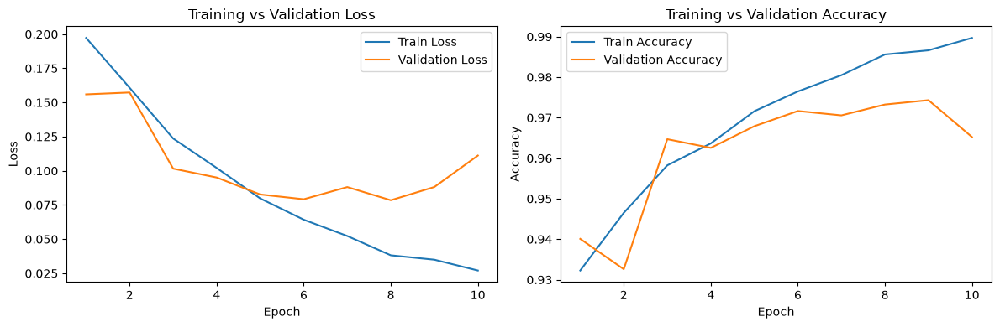

In [125]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="Train Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


In [126]:

import copy

best_val_loss = float("inf")
best_model_state = None

EPOCHS = 10

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_validator_loader,
        criterion, optimizer, device
    )

    val_loss, val_acc = validate_one_epoch(
        model, val_validator_loader,
        criterion, device
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

model.load_state_dict(best_model_state)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_to_idx": train_validator_dataset.class_to_idx,
        "class_names": train_validator_dataset.classes,
        "image_size": 64,
        "mean": (0.5, 0.5, 0.5),
        "std": (0.5, 0.5, 0.5)
    },
    BASE_DIR / "models" / "tomato_validator_best.pth"
)


Epoch [1/10] Train Loss: 0.0181 Train Acc: 0.9926 Val Loss: 0.1126 Val Acc: 0.9684
Epoch [2/10] Train Loss: 0.0237 Train Acc: 0.9915 Val Loss: 0.1261 Val Acc: 0.9679
Epoch [3/10] Train Loss: 0.0219 Train Acc: 0.9929 Val Loss: 0.0948 Val Acc: 0.9706
Epoch [4/10] Train Loss: 0.0114 Train Acc: 0.9954 Val Loss: 0.1299 Val Acc: 0.9690
Epoch [5/10] Train Loss: 0.0137 Train Acc: 0.9960 Val Loss: 0.1048 Val Acc: 0.9722
Epoch [6/10] Train Loss: 0.0174 Train Acc: 0.9945 Val Loss: 0.1074 Val Acc: 0.9716
Epoch [7/10] Train Loss: 0.0111 Train Acc: 0.9961 Val Loss: 0.1277 Val Acc: 0.9706
Epoch [8/10] Train Loss: 0.0160 Train Acc: 0.9946 Val Loss: 0.1280 Val Acc: 0.9722
Epoch [9/10] Train Loss: 0.0081 Train Acc: 0.9978 Val Loss: 0.1014 Val Acc: 0.9738
Epoch [10/10] Train Loss: 0.0136 Train Acc: 0.9964 Val Loss: 0.1345 Val Acc: 0.9727


In [127]:
test_loss, test_acc = validate_one_epoch(
    model,
    test_validator_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 0.0745
Test Accuracy: 0.9767


In [128]:

from sklearn.metrics import confusion_matrix, classification_report
import torch

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_validator_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.tolist())

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_validator_dataset.classes,
    digits=4
))


Confusion Matrix:
[[ 667   28]
 [  18 1258]]

Classification Report:
                 precision    recall  f1-score   support

not_tomato_leaf     0.9737    0.9597    0.9667       695
    tomato_leaf     0.9782    0.9859    0.9820      1276

       accuracy                         0.9767      1971
      macro avg     0.9760    0.9728    0.9744      1971
   weighted avg     0.9766    0.9767    0.9766      1971



In [129]:

from collections import Counter

# Count test examples by their original source
source_counts = Counter()

for path, label in test_validator_dataset.samples:
    if label == 0:
        if "PlantDisease" in path:
            source_counts["PlantDisease"] += 1
        elif "negative_images" in path:
            source_counts["CIFAR-10"] += 1

print(source_counts)


Counter()


In [130]:
from pathlib import Path

negative_dir = validator_dir / "test" / "not_tomato_leaf"

for path in list(negative_dir.iterdir())[:10]:
    print(path.name)

cifar_test_1.jpg
cifar_test_1013.jpg
cifar_test_1037.jpg
cifar_test_104.jpg
cifar_test_105.jpg
cifar_test_106.jpg
cifar_test_1072.jpg
cifar_test_11.jpg
cifar_test_110.jpg
cifar_test_1173.jpg


In [131]:
from collections import Counter

source_counts = Counter()

for path, label in test_validator_dataset.samples:

    if label == 0:
        filename = Path(path).name

        if filename.startswith("cifar_test_"):
            source_counts["CIFAR-10"] += 1
        elif filename.startswith("PlantDisease_"):
            source_counts["PlantDisease"] += 1
        else:
            source_counts["Unknown"] += 1

print(source_counts)

Counter({'CIFAR-10': 500, 'Unknown': 195})


In [132]:
unknown_files = []

for path, label in test_validator_dataset.samples:
    if label == 0:
        filename = Path(path).name

        if not filename.startswith("cifar_test_"):
            unknown_files.append(filename)

print("Total:", len(unknown_files))
print(*unknown_files[:15], sep="\n")

Total: 195
plant_Apple___Apple_scab_0.jpg
plant_Apple___Apple_scab_1.jpg
plant_Apple___Apple_scab_10.jpg
plant_Apple___Apple_scab_11.jpg
plant_Apple___Apple_scab_12.jpg
plant_Apple___Apple_scab_13.jpg
plant_Apple___Apple_scab_14.jpg
plant_Apple___Apple_scab_2.jpg
plant_Apple___Apple_scab_3.jpg
plant_Apple___Apple_scab_4.jpg
plant_Apple___Apple_scab_5.jpg
plant_Apple___Apple_scab_6.jpg
plant_Apple___Apple_scab_7.jpg
plant_Apple___Apple_scab_8.jpg
plant_Apple___Apple_scab_9.jpg


In [133]:

from collections import defaultdict
from pathlib import Path

model.eval()

all_test_predictions = []

with torch.no_grad():
    for images, labels in test_validator_loader:
        images = images.to(device)
        outputs = model(images)

        predictions = outputs.argmax(dim=1).cpu().tolist()
        all_test_predictions.extend(predictions)

source_results = defaultdict(
    lambda: {"rejected": 0, "accepted": 0}
)

for (image_path, actual_label), prediction in zip(
    test_validator_dataset.samples,
    all_test_predictions
):
    if actual_label != 0:
        continue

    filename = Path(image_path).name

    if filename.startswith("cifar_test_"):
        source = "CIFAR-10"
    elif filename.startswith("plant_"):
        source = "PlantDisease"
    else:
        source = "Unknown"

    if prediction == 0:
        source_results[source]["rejected"] += 1
    else:
        source_results[source]["accepted"] += 1

for source, results in source_results.items():

    total = results["rejected"] + results["accepted"]
    rejection_rate = results["rejected"] / total

    print(f"\n{source}")
    print("Total:", total)
    print("Correctly rejected:", results["rejected"])
    print("Mistakenly accepted:", results["accepted"])
    print(f"Rejection rate: {rejection_rate:.4%}")



CIFAR-10
Total: 500
Correctly rejected: 499
Mistakenly accepted: 1
Rejection rate: 99.8000%

PlantDisease
Total: 195
Correctly rejected: 168
Mistakenly accepted: 27
Rejection rate: 86.1538%


In [135]:
from collections import defaultdict
from pathlib import Path

plant_errors = defaultdict(int)
plant_totals = defaultdict(int)

for (image_path, actual_label), prediction in zip(
    test_validator_dataset.samples,
    all_test_predictions
):
    filename = Path(image_path).stem

    if filename.startswith("plant_"):
        class_name = filename[len("plant_"):].rsplit("_", 1)[0]

        plant_totals[class_name] += 1

        if prediction == 1:
            plant_errors[class_name] += 1

for class_name, total in plant_totals.items():
    errors = plant_errors[class_name]
    print(f"{class_name}: {errors}/{total} mistakenly accepted")

Apple___Apple_scab: 2/15 mistakenly accepted
Apple___Black_rot: 6/15 mistakenly accepted
Apple___Cedar_apple_rust: 4/15 mistakenly accepted
Apple___healthy: 2/15 mistakenly accepted
Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot: 2/15 mistakenly accepted
Corn_(maize)___Common_rust_: 1/15 mistakenly accepted
Corn_(maize)___Northern_Leaf_Blight: 1/15 mistakenly accepted
Corn_(maize)___healthy: 0/15 mistakenly accepted
Pepper__bell___Bacterial_spot: 4/15 mistakenly accepted
Pepper__bell___healthy: 0/15 mistakenly accepted
Potato___Early_blight: 0/15 mistakenly accepted
Potato___Late_blight: 4/15 mistakenly accepted
Potato___healthy: 1/15 mistakenly accepted


In [136]:
for (image_path, actual_label), prediction in zip(
    test_validator_dataset.samples,
    all_test_predictions
):
    filename = Path(image_path).stem

    if filename.startswith("plant_"):
        class_name = filename[len("plant_"):].rsplit("_", 1)[0]

        plant_totals[class_name] += 1

        if prediction == 1:
            plant_errors[class_name] += 1

for class_name, total in plant_totals.items():
    errors = plant_errors[class_name]
    print(f"{class_name}: {errors}/{total} mistakenly accepted")

Apple___Apple_scab: 4/30 mistakenly accepted
Apple___Black_rot: 12/30 mistakenly accepted
Apple___Cedar_apple_rust: 8/30 mistakenly accepted
Apple___healthy: 4/30 mistakenly accepted
Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot: 4/30 mistakenly accepted
Corn_(maize)___Common_rust_: 2/30 mistakenly accepted
Corn_(maize)___Northern_Leaf_Blight: 2/30 mistakenly accepted
Corn_(maize)___healthy: 0/30 mistakenly accepted
Pepper__bell___Bacterial_spot: 8/30 mistakenly accepted
Pepper__bell___healthy: 0/30 mistakenly accepted
Potato___Early_blight: 0/30 mistakenly accepted
Potato___Late_blight: 8/30 mistakenly accepted
Potato___healthy: 2/30 mistakenly accepted


Total false acceptances: 27


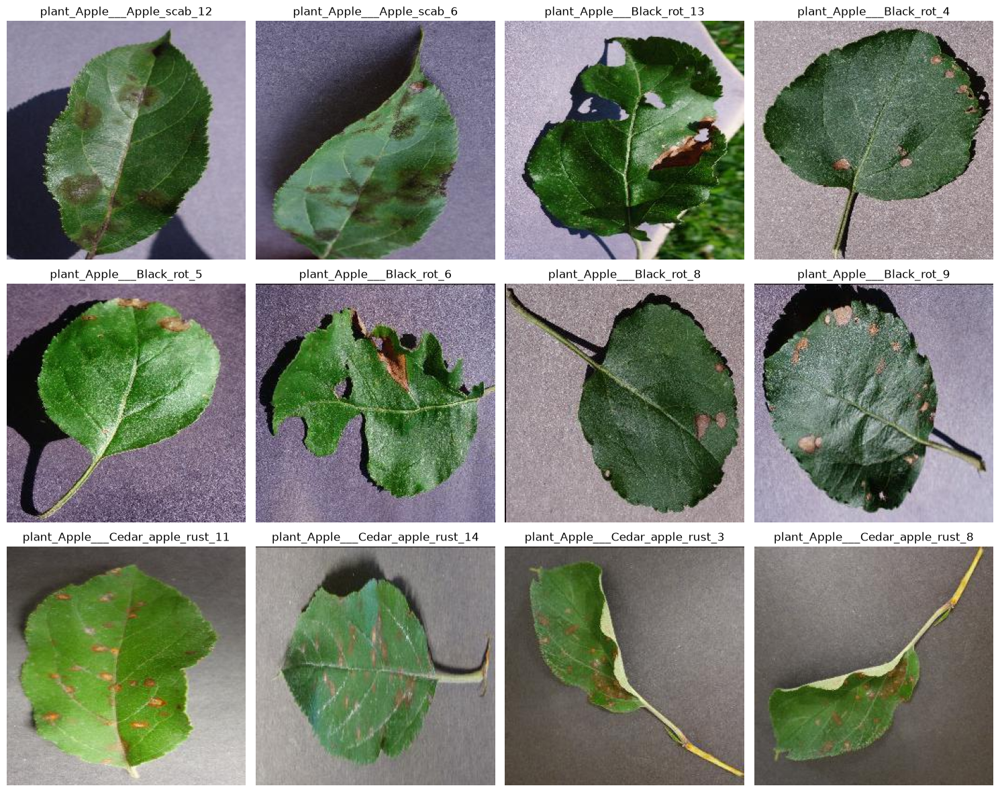

In [137]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

false_accepts = []

for (image_path, actual_label), prediction in zip(
    test_validator_dataset.samples,
    all_test_predictions
):
    filename = Path(image_path).name

    if filename.startswith("plant_") and prediction == 1:
        false_accepts.append(image_path)

print("Total false acceptances:", len(false_accepts))

plt.figure(figsize=(15, 12))

for i, image_path in enumerate(false_accepts[:12]):
    image = Image.open(image_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(Path(image_path).stem[:35])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [138]:
false_accept_details = []

model.eval()

with torch.no_grad():
    for image_path in false_accepts:
        image = Image.open(image_path).convert("RGB")
        image_tensor = validator_transform(image).unsqueeze(0).to(device)

        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)

        tomato_probability = probabilities[0, 1].item()

        false_accept_details.append(
            (Path(image_path).name, tomato_probability)
        )

for filename, probability in false_accept_details:
    print(f"{filename}: {probability:.4%}")

plant_Apple___Apple_scab_12.jpg: 61.0179%
plant_Apple___Apple_scab_6.jpg: 52.8759%
plant_Apple___Black_rot_13.jpg: 87.0800%
plant_Apple___Black_rot_4.jpg: 96.0708%
plant_Apple___Black_rot_5.jpg: 96.8464%
plant_Apple___Black_rot_6.jpg: 89.3460%
plant_Apple___Black_rot_8.jpg: 96.0222%
plant_Apple___Black_rot_9.jpg: 99.9629%
plant_Apple___Cedar_apple_rust_11.jpg: 99.8009%
plant_Apple___Cedar_apple_rust_14.jpg: 78.9914%
plant_Apple___Cedar_apple_rust_3.jpg: 73.9399%
plant_Apple___Cedar_apple_rust_8.jpg: 98.2436%
plant_Apple___healthy_12.jpg: 63.1079%
plant_Apple___healthy_14.jpg: 73.8139%
plant_Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot_11.jpg: 87.0955%
plant_Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot_13.jpg: 95.2674%
plant_Corn_(maize)___Common_rust__9.jpg: 98.9195%
plant_Corn_(maize)___Northern_Leaf_Blight_3.jpg: 57.5645%
plant_Pepper__bell___Bacterial_spot_10.jpg: 92.0661%
plant_Pepper__bell___Bacterial_spot_11.jpg: 68.5808%
plant_Pepper__bell___Bacterial_spot_5.jpg: 71.

In [139]:
from collections import Counter
from pathlib import Path

train_counts = Counter()

for image_path, label in train_validator_dataset.samples:
    if label == 0:
        filename = Path(image_path).stem
        class_name = filename[len("plant_"):].rsplit("_", 1)[0]

        if filename.startswith("plant_"):
            train_counts[class_name] += 1

for class_name, count in sorted(train_counts.items()):
    print(f"{class_name}: {count}")

Apple___Apple_scab: 70
Apple___Black_rot: 70
Apple___Cedar_apple_rust: 70
Apple___healthy: 70
Corn_(maize)___Cercospora_leaf_spot_Gray_leaf_spot: 70
Corn_(maize)___Common_rust_: 70
Corn_(maize)___Northern_Leaf_Blight: 70
Corn_(maize)___healthy: 70
Pepper__bell___Bacterial_spot: 70
Pepper__bell___healthy: 70
Potato___Early_blight: 70
Potato___Late_blight: 70
Potato___healthy: 70


In [140]:
from pathlib import Path
import torch

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Save validator
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_validator_dataset.class_to_idx,
    "image_size": 64,
    "mean": (0.5, 0.5, 0.5),
    "std": (0.5, 0.5, 0.5)
}, MODEL_DIR / "tomato_validator.pth")

# Check existing disease classifier
disease_checkpoint = MODEL_DIR / "tomato_cnn_final.pth"

print("Validator saved.")
print("Disease classifier exists:", disease_checkpoint.exists())

Validator saved.
Disease classifier exists: True


In [141]:
# Load both checkpoints
validator_checkpoint = torch.load(
    MODEL_DIR / "tomato_validator.pth",
    map_location=device,
    weights_only=True
)

disease_checkpoint = torch.load(
    MODEL_DIR / "tomato_cnn_final.pth",
    map_location=device,
    weights_only=True
)

print("VALIDATOR CHECKPOINT")
print(validator_checkpoint.keys())

print("\nDISEASE CLASSIFIER CHECKPOINT")
print(disease_checkpoint.keys())

print("\nDisease classes:")
print(disease_checkpoint["class_names"])

VALIDATOR CHECKPOINT
dict_keys(['model_state_dict', 'class_to_idx', 'image_size', 'mean', 'std'])

DISEASE CLASSIFIER CHECKPOINT
dict_keys(['model_state_dict', 'class_names', 'class_to_idx', 'image_size', 'mean', 'std'])

Disease classes:
['Tomato___Bacterial_spot', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']


In [142]:
class TomatoValidatorCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [143]:
class TomatoCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [144]:
validator_model = TomatoValidatorCNN().to(device)
validator_model.load_state_dict(
    validator_checkpoint["model_state_dict"]
)

disease_model = TomatoCNN().to(device)
disease_model.load_state_dict(
    disease_checkpoint["model_state_dict"]
)

validator_model.eval()
disease_model.eval()

print("Both models loaded successfully!")

Both models loaded successfully!


In [145]:
dummy_input = torch.randn(1, 3, 64, 64).to(device)

with torch.no_grad():
    validator_output = validator_model(dummy_input)
    disease_output = disease_model(dummy_input)

print("Validator output:", validator_output.shape)
print("Disease output:", disease_output.shape)

Validator output: torch.Size([1, 2])
Disease output: torch.Size([1, 5])


In [165]:
from PIL import Image

validator_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

disease_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])


def predict_tomato(image):

    image = image.convert("RGB")

    # STAGE 1: Check whether the image is a tomato leaf
    validator_input = validator_transform(image).unsqueeze(0).to(device)

    validator_model.eval()

    with torch.no_grad():
        validator_output = validator_model(validator_input)

        # Convert model output into probabilities
        validator_probs = torch.softmax(validator_output, dim=1)

        # Probability that this is a tomato leaf (class 1)
        tomato_probability = validator_probs[0, 1].item()

    # Apply threshold
    if tomato_probability < 0.50:
        return {
            "status": "rejected",
            "message": "This image was not identified as a tomato leaf.",
            "confidence": 1 - tomato_probability
        }

    # STAGE 2: Identify the tomato leaf condition
    disease_input = disease_transform(image).unsqueeze(0).to(device)

    disease_model.eval()

    with torch.no_grad():
        disease_output = disease_model(disease_input)

        disease_probs = torch.softmax(disease_output, dim=1)

        disease_prediction = disease_probs.argmax(dim=1).item()

        disease_confidence = disease_probs[0, disease_prediction].item()

    disease_name = disease_checkpoint["class_names"][disease_prediction]

    return {
        "status": "accepted",
        "disease": disease_name,
        "confidence": disease_confidence
    }

In [181]:
from PIL import Image
import torch

def test_disease_classifier(image_path):
    image = Image.open(image_path).convert("RGB")

    image_tensor = disease_transform(image).unsqueeze(0).to(device)

    disease_model.eval()

    with torch.no_grad():
        output = disease_model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0]

    for i, class_name in enumerate(disease_checkpoint["class_names"]):
        print(
            f"{class_name.replace('Tomato___', '')}: "
            f"{probabilities[i].item() * 100:.2f}%"
        )

    prediction = probabilities.argmax().item()

    print("\nPredicted class:",
          disease_checkpoint["class_names"][prediction])

In [166]:
print("Disease test classes:", test_dataset.classes)
print("Disease test images:", len(test_dataset))

Disease test classes: ['Tomato___Bacterial_spot', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']
Disease test images: 1276


In [167]:
from pathlib import Path
from PIL import Image
from collections import Counter

validator_model.eval()
disease_model.eval()

# Counters
total_tomato = 0
correct_disease = 0
rejected_tomato = 0
wrong_disease = 0

total_negative = 0
correctly_rejected = 0
false_acceptances = 0

# Evaluate all tomato images
for image_path, true_label in test_dataset.samples:

    image = Image.open(image_path).convert("RGB")
    result = predict_tomato(image)

    total_tomato += 1

    if result["status"] == "rejected":
        rejected_tomato += 1

    else:
        predicted_name = result["disease"]
        true_name = test_dataset.classes[true_label]

        if predicted_name == true_name:
            correct_disease += 1
        else:
            wrong_disease += 1

# Evaluate all non-tomato images
for image_path, label in test_validator_dataset.samples:

    if label != 0:
        continue

    image = Image.open(image_path).convert("RGB")
    result = predict_tomato(image)

    total_negative += 1

    if result["status"] == "rejected":
        correctly_rejected += 1
    else:
        false_acceptances += 1

# Results
print("TOMATO IMAGES")
print("Total:", total_tomato)
print("Correct disease predictions:", correct_disease)
print("Wrong disease predictions:", wrong_disease)
print("Incorrectly rejected:", rejected_tomato)

print("\nNON-TOMATO IMAGES")
print("Total:", total_negative)
print("Correctly rejected:", correctly_rejected)
print("Incorrectly accepted:", false_acceptances)

total_images = total_tomato + total_negative
total_correct = correct_disease + correctly_rejected

print("\nEND-TO-END RESULTS")
print("Total images:", total_images)
print("Correct final outcomes:", total_correct)
print(f"Overall accuracy: {total_correct / total_images:.4%}")

TOMATO IMAGES
Total: 1276
Correct disease predictions: 1236
Wrong disease predictions: 22
Incorrectly rejected: 18

NON-TOMATO IMAGES
Total: 695
Correctly rejected: 667
Incorrectly accepted: 28

END-TO-END RESULTS
Total images: 1971
Correct final outcomes: 1903
Overall accuracy: 96.5500%


In [180]:
import gradio as gr

def gradio_predict(image):
    if image is None:
        return "Please upload an image first."

    result = predict_tomato(image)

    if result["status"] == "rejected":
        confidence = result["confidence"] * 100
        
        return (
            "❌ Image rejected\n\n"
            "This image did not pass the tomato-leaf verification stage.\n\n"
            "Please upload a clear image of a tomato leaf."
            "\n\n"
            f"Non-tomato confidence: {confidence:.2f}%"
)
    disease = (
        result["disease"]
        .replace("Tomato___", "")
        .replace("_", " ")
    )

    confidence = result["confidence"] * 100

    return (
        "✅ Tomato leaf detected!\n\n"
        f"Predicted condition: {disease}\n\n"
        f"Classification confidence: {confidence:.2f}%\n\n"
        "Note: This is an AI prediction and should not be "
        "treated as a definitive plant-health diagnosis."
    )


demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(
        type="pil",
        label="Upload a plant leaf image"
    ),
    outputs=gr.Textbox(
        label="Analysis result",
        lines=7
    ),
    title="Tomato Leaf Disease Detection System",
    description=(
        "An AI-powered two-stage system that checks whether "
        "an uploaded image is a tomato leaf and predicts "
        "its condition."
    ),
    theme=gr.themes.Soft()
)

demo.launch()


C:\Users\pc\miniconda3\envs\deeplearning\Lib\site-packages\gradio\interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.


Created dataset file at: .gradio\flagged\dataset1.csv


In [174]:
rejected_tomato_images = []

for image_path, true_label in test_dataset.samples:

    image = Image.open(image_path).convert("RGB")
    image_tensor = validator_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = validator_model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)

    tomato_probability = probabilities[0, 1].item()

    if tomato_probability < 0.5:
        rejected_tomato_images.append(
            (image_path, tomato_probability)
        )

print("Rejected tomato images:", len(rejected_tomato_images))

for path, probability in rejected_tomato_images:
    print(f"{Path(path).name}: {probability:.2%}")

Rejected tomato images: 18
1b3ccbf3-c1e1-476e-b34a-6af0a6fbb349___GCREC_Bact.Sp 3735.JPG: 35.22%
4378c0ca-ff9f-48f4-8311-e716e89b1a99___RS_Late.B 5087.JPG: 2.31%
9ec6c8fd-4dfe-4dc6-bc1f-72488053da67___GHLB Leaf 2.4 Day 12.JPG: 6.53%
a9d292cb-2aaf-44cd-a1ef-bec9b05308b9___RS_Late.B 7005.JPG: 7.01%
afb65a40-7512-4d2c-884e-56e6c5010511___RS_Late.B 5380.JPG: 32.73%
0b6a9374-858d-49ce-8a94-ab57c957718c___Matt.S_CG 2488.JPG: 0.36%
390beb09-e4d3-4248-bb1c-7cefbd45a8d1___Matt.S_CG 6507.JPG: 36.77%
45c5dbd2-e45d-438b-ae11-04e96417cb2f___Matt.S_CG 0666.JPG: 13.96%
4f35adfa-03b3-4562-b970-19548dda84d1___Matt.S_CG 2457.JPG: 23.48%
5418736d-c947-4cdc-b82c-692de712880a___JR_Sept.L.S 2619.JPG: 33.92%
69624cd3-6e0a-4853-a830-7ad1b67bbcbd___Matt.S_CG 7575.JPG: 44.13%
96b822e7-9d51-40d2-9a1f-b4125446531b___Matt.S_CG 7397.JPG: 49.71%
eee7ded5-b391-41df-b31d-71e663d03cb9___JR_Sept.L.S 2622.JPG: 0.36%
573bb735-f530-4b6b-8004-79abe8e4c53b___YLCV_GCREC 1915.JPG: 25.99%
ab592870-b6d1-42a1-8169-e9c5b797c497___

In [175]:
import numpy as np
from sklearn.metrics import confusion_matrix

validator_model.eval()

val_probabilities = []
val_labels = []

with torch.no_grad():
    for images, labels in val_validator_loader:
        images = images.to(device)

        outputs = validator_model(images)
        probabilities = torch.softmax(outputs, dim=1)

        val_probabilities.extend(
            probabilities[:, 1].cpu().numpy()
        )

        val_labels.extend(labels.numpy())

val_probabilities = np.array(val_probabilities)
val_labels = np.array(val_labels)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:

    predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    tomato_recall = tp / (tp + fn)
    negative_rejection = tn / (tn + fp)

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Tomato acceptance: {tomato_recall:.2%}")
    print(f"Non-tomato rejection: {negative_rejection:.2%}")
    print(f"False tomato acceptances: {fp}")
    print(f"False tomato rejections: {fn}")


Threshold: 0.30
Tomato acceptance: 98.59%
Non-tomato rejection: 92.27%
False tomato acceptances: 46
False tomato rejections: 18

Threshold: 0.35
Tomato acceptance: 98.59%
Non-tomato rejection: 92.44%
False tomato acceptances: 45
False tomato rejections: 18

Threshold: 0.40
Tomato acceptance: 98.59%
Non-tomato rejection: 93.45%
False tomato acceptances: 39
False tomato rejections: 18

Threshold: 0.45
Tomato acceptance: 98.51%
Non-tomato rejection: 93.61%
False tomato acceptances: 38
False tomato rejections: 19

Threshold: 0.50
Tomato acceptance: 98.43%
Non-tomato rejection: 94.12%
False tomato acceptances: 35
False tomato rejections: 20


In [182]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

test_folders = [
    "Tomato___Bacterial_spot",
    "Tomato___Late_blight",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___healthy"
]

for folder in test_folders:
    folder_path = BASE_DIR / "data" / "raw" / folder

    images = list(folder_path.glob("*.jpg"))

    print(folder, ":", len(images), "images")

Tomato___Bacterial_spot : 0 images
Tomato___Late_blight : 0 images
Tomato___Septoria_leaf_spot : 0 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus : 0 images
Tomato___healthy : 0 images


In [183]:
from PIL import Image

for folder in test_folders:

    folder_path = BASE_DIR / "data" / "raw" / folder
    image_path = list(folder_path.glob("*.jpg"))[0]

    image = Image.open(image_path).convert("RGB")

    result = predict_tomato(image)

    print("\nActual class:", folder.replace("Tomato___", ""))
    print("Prediction:", result)

IndexError: list index out of range

In [184]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

print("Current notebook directory:", Path.cwd())
print("Project directory:", BASE_DIR)

for folder in ["data", "data/raw", "data/train", "data/validation", "data/test"]:
    path = BASE_DIR / folder
    print(f"\n{folder}:")
    if path.exists():
        print([item.name for item in path.iterdir()][:10])
    else:
        print("Directory does not exist")

Current notebook directory: C:\Users\pc\CropDiseaseDetection\notebooks
Project directory: C:\Users\pc\CropDiseaseDetection

data:
['external', 'raw', 'validator_dataset']

data/raw:
['Tomato Early blight', 'Tomato healthy', 'Tomato Late blight']

data/train:
Directory does not exist

data/validation:
Directory does not exist

data/test:
Directory does not exist


In [185]:
raw_dir = BASE_DIR / "data" / "raw"

print("RAW DIRECTORY EXISTS:", raw_dir.exists())

for item in raw_dir.iterdir():
    print("\nFolder:", item.name)

    if item.is_dir():
        files = list(item.iterdir())
        print("Number of items:", len(files))
        print("First 5 items:", [f.name for f in files[:5]])

RAW DIRECTORY EXISTS: True

Folder: Tomato Early blight
Number of items: 1
First 5 items: ['sample.jpg']

Folder: Tomato healthy
Number of items: 2
First 5 items: ['image_0001.jpg', 'sample.jpg']

Folder: Tomato Late blight
Number of items: 6
First 5 items: ['image_0001.jpg', 'image_0002.jpg', 'image_0003.jpg', 'image_0004.jpg', 'image_0005.jpg']


In [186]:
print("Test dataset classes:")

for class_name in test_dataset.classes:
    print(class_name)

Test dataset classes:
Tomato___Bacterial_spot
Tomato___Late_blight
Tomato___Septoria_leaf_spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___healthy


In [187]:
from PIL import Image

for class_name in test_dataset.classes:

    image_path = next(
        Path(path)
        for path, label in test_dataset.samples
        if label == test_dataset.class_to_idx[class_name]
    )

    image = Image.open(image_path).convert("RGB")

    result = predict_tomato(image)

    print("\nActual class:", class_name.replace("Tomato___", ""))
    print("Prediction:", result)


Actual class: Bacterial_spot
Prediction: {'status': 'accepted', 'disease': 'Tomato___Bacterial_spot', 'confidence': 0.9970182180404663}

Actual class: Late_blight
Prediction: {'status': 'accepted', 'disease': 'Tomato___Late_blight', 'confidence': 0.99982750415802}

Actual class: Septoria_leaf_spot
Prediction: {'status': 'accepted', 'disease': 'Tomato___Septoria_leaf_spot', 'confidence': 0.9964427351951599}

Actual class: Tomato_Yellow_Leaf_Curl_Virus
Prediction: {'status': 'accepted', 'disease': 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'confidence': 0.9999698400497437}

Actual class: healthy
Prediction: {'status': 'accepted', 'disease': 'Tomato___healthy', 'confidence': 0.9990838766098022}


In [188]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

for item in sorted(BASE_DIR.iterdir()):
    if item.is_dir():
        print(f"\n📁 {item.name}/")

        for child in sorted(item.iterdir()):
            if child.is_dir():
                print(f"    📁 {child.name}/")
            else:
                print(f"    📄 {child.name}")
    else:
        print(f"📄 {item.name}")


📁 app/

📁 data/
    📁 external/
    📁 raw/
    📁 validator_dataset/

📁 jupyter_runtime/
    📄 jpserver-11732-open.html
    📄 jpserver-11732.json
    📄 jpserver-11764-open.html
    📄 jpserver-11764.json
    📄 jpserver-12824-open.html
    📄 jpserver-12824.json
    📄 jpserver-2736-open.html
    📄 jpserver-2736.json
    📄 jpserver-6900-open.html
    📄 jpserver-6900.json
    📄 jupyter_cookie_secret
    📄 kernel-0b6eb818-b99e-40bf-b144-829118f27263.json
    📄 kernel-29102efc-d73f-472c-b3f2-ea7520854f55.json
    📄 kernel-30332cf6-e184-4a1a-ac7a-5520c704b7c1.json
    📄 kernel-3220e568-9aea-4973-a451-ad8746713d18.json
    📄 kernel-37393348-d5f2-41da-9f76-c43d29bce820.json
    📄 kernel-388f4c39-c664-4727-8af0-a554eaa34811.json
    📄 kernel-8c908d2f-4073-4efd-9f89-cd3b9f40cf5b.json
    📄 kernel-bbfe42e9-037d-41b4-97d9-c4a3405b09fd.json
    📄 kernel-c40ece1e-041e-41d8-8a7e-2c48c77668c0.json
    📄 kernel-d1434e69-a49b-423b-9783-fa4333bc5c6a.json
    📄 kernel-f723f695-0e1f-4b51-a699-9ee30c6a05b1.js

In [189]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

folders_to_inspect = [
    "app",
    "src",
    "models",
    "notebooks",
    "quarantine"
]

for folder in folders_to_inspect:
    folder_path = BASE_DIR / folder

    print(f"\n{'='*15} {folder} {'='*15}")

    for path in sorted(folder_path.rglob("*")):
        if path.is_file():
            size_mb = path.stat().st_size / (1024 * 1024)
            print(f"{path.relative_to(BASE_DIR)} — {size_mb:.2f} MB")


=============== app ===============

=============== src ===============

=============== models ===============
models\best_model.pth — 2.10 MB
models\tomato_cnn_final.pth — 2.10 MB
models\tomato_validator.pth — 2.10 MB
models\tomato_validator_best.pth — 2.10 MB

=============== notebooks ===============
notebooks\.gradio\flagged\dataset1.csv — 0.00 MB
notebooks\.gradio\flagged\Upload a plant leaf image\22a51cabd9571af2f981\images..jpg — 0.06 MB
notebooks\.ipynb_checkpoints\01_dataset_exploration-checkpoint.ipynb — 0.00 MB
notebooks\01_dataset_exploration.ipynb — 11.44 MB
notebooks\best_model.pth — 2.10 MB

=============== quarantine ===============
quarantine\test\Tomato___healthy\9662364c-aaba-45e3-b907-10792d60578c___GH_HL Leaf 220.JPG — 0.02 MB
quarantine\test\Tomato___Late_blight\3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg — 0.01 MB
quarantine\validation\Tomato___Late_blight\1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG — 0.01 MB
quarantine\val

In [190]:
print("\nPROJECT ROOT FILES")

for path in BASE_DIR.iterdir():
    if path.is_file():
        print(path.name)


PROJECT ROOT FILES


In [191]:
import hashlib
from pathlib import Path

BASE_DIR = Path.cwd().parent

model_files = [
    BASE_DIR / "models" / "best_model.pth",
    BASE_DIR / "models" / "tomato_cnn_final.pth",
    BASE_DIR / "models" / "tomato_validator.pth",
    BASE_DIR / "models" / "tomato_validator_best.pth",
    BASE_DIR / "notebooks" / "best_model.pth"
]

for path in model_files:
    if path.exists():
        file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        print(f"\n{path.relative_to(BASE_DIR)}")
        print(file_hash)


models\best_model.pth
1ff5ff449a7bbb3318d2d778c3564a84a23c4ec48201c6fb8ef0ac7b46e8619f

models\tomato_cnn_final.pth
e446656ae7a5542950cceed77719bbc38b79f050da24389be0091945962cab98

models\tomato_validator.pth
9df893893eebd493bf477b999ab45c294b08d1d2762dc0af39574c7b1ab4bcb7

models\tomato_validator_best.pth
207418fb4e45a4b29a54d0ded1ebb5af159728896b2fa78e55a9ceb502229a4a

notebooks\best_model.pth
e25a4b7540158b51bff057d951289c30274194429ca6aa08e639b5bbd027be02


In [192]:
import torch
from pathlib import Path

BASE_DIR = Path.cwd().parent

model_files = [
    BASE_DIR / "models" / "best_model.pth",
    BASE_DIR / "models" / "tomato_cnn_final.pth",
    BASE_DIR / "models" / "tomato_validator.pth",
    BASE_DIR / "models" / "tomato_validator_best.pth",
    BASE_DIR / "notebooks" / "best_model.pth"
]

for path in model_files:
    print("\n" + "=" * 55)
    print("FILE:", path.relative_to(BASE_DIR))

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict):
        print("Keys:", list(checkpoint.keys()))

        for key in ["class_names", "class_to_idx", "image_size"]:
            if key in checkpoint:
                print(f"{key}:", checkpoint[key])


FILE: models\best_model.pth
Checkpoint type: OrderedDict
Keys: ['features.0.weight', 'features.0.bias', 'features.3.weight', 'features.3.bias', 'features.6.weight', 'features.6.bias', 'classifier.1.weight', 'classifier.1.bias', 'classifier.4.weight', 'classifier.4.bias']

FILE: models\tomato_cnn_final.pth
Checkpoint type: dict
Keys: ['model_state_dict', 'class_names', 'class_to_idx', 'image_size', 'mean', 'std']
class_names: ['Tomato___Bacterial_spot', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']
class_to_idx: {'Tomato___Bacterial_spot': 0, 'Tomato___Late_blight': 1, 'Tomato___Septoria_leaf_spot': 2, 'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 3, 'Tomato___healthy': 4}
image_size: 64

FILE: models\tomato_validator.pth
Checkpoint type: dict
Keys: ['model_state_dict', 'class_to_idx', 'image_size', 'mean', 'std']
class_to_idx: {'not_tomato_leaf': 0, 'tomato_leaf': 1}
image_size: 64

FILE: models\tomato_validator_best.p

In [193]:

import torch
from sklearn.metrics import confusion_matrix, accuracy_score

validator_checkpoints = {
    "Current validator": BASE_DIR / "models" / "tomato_validator.pth",
    "Best validator": BASE_DIR / "models" / "tomato_validator_best.pth"
}

for name, checkpoint_path in validator_checkpoints.items():

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    candidate = TomatoValidatorCNN().to(device)
    candidate.load_state_dict(checkpoint["model_state_dict"])
    candidate.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_validator_loader:
            images = images.to(device)

            outputs = candidate(images)
            probabilities = torch.softmax(outputs, dim=1)

            predictions = probabilities.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    print("\n", "=" * 40)
    print(name)
    print("Accuracy:", round(accuracy_score(
        all_labels, all_predictions
    ) * 100, 2), "%")

    print("Non-tomato rejection:",
          round(tn / (tn + fp) * 100, 2), "%")

    print("Tomato acceptance:",
          round(tp / (tp + fn) * 100, 2), "%")

    print("False tomato acceptances:", fp)
    print("False tomato rejections:", fn)



Current validator
Accuracy: 97.06 %
Non-tomato rejection: 94.12 %
Tomato acceptance: 98.43 %
False tomato acceptances: 35
False tomato rejections: 20

Best validator
Accuracy: 97.06 %
Non-tomato rejection: 94.12 %
Tomato acceptance: 98.43 %
False tomato acceptances: 35
False tomato rejections: 20


In [194]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

(BASE_DIR / "src" / "models.py").write_text(
    "# Model architectures for Tomato Disease Detection\n",
    encoding="utf-8"
)

print("Created:", BASE_DIR / "src" / "models.py")

Created: C:\Users\pc\CropDiseaseDetection\src\models.py


In [195]:

import torch.nn as nn


class TomatoCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


class TomatoValidatorCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


In [196]:
(BASE_DIR / "src" / "prediction.py").write_text(
    "# Prediction pipeline\n",
    encoding="utf-8"
)

22

In [198]:

from pathlib import Path

import torch
from torchvision import transforms

import sys
sys.path.insert(0, str(Path(__file__).resolve().parent))

from models import TomatoCNN, TomatoValidatorCNN


# Project paths
BASE_DIR = Path(__file__).resolve().parent.parent
MODEL_DIR = BASE_DIR / "models"

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# Load checkpoints
disease_checkpoint = torch.load(
    MODEL_DIR / "tomato_cnn_final.pth",
    map_location=device,
    weights_only=True
)

validator_checkpoint = torch.load(
    MODEL_DIR / "tomato_validator.pth",
    map_location=device,
    weights_only=True
)


# Reconstruct models
disease_model = TomatoCNN().to(device)
disease_model.load_state_dict(
    disease_checkpoint["model_state_dict"]
)
disease_model.eval()


validator_model = TomatoValidatorCNN().to(device)
validator_model.load_state_dict(
    validator_checkpoint["model_state_dict"]
)
validator_model.eval()


# Image transformations
disease_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=disease_checkpoint["mean"],
        std=disease_checkpoint["std"]
    )
])

validator_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=validator_checkpoint["mean"],
        std=validator_checkpoint["std"]
    )
])


# Complete prediction pipeline
def predict_tomato(image):

    image = image.convert("RGB")

    # Stage 1: Tomato leaf verification
    validator_input = validator_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        validator_output = validator_model(
            validator_input
        )

        validator_probs = torch.softmax(
            validator_output, dim=1
        )

        tomato_probability = validator_probs[0, 1].item()

    if tomato_probability < 0.50:
        return {
            "status": "rejected",
            "message": (
                "This image did not pass "
                "the tomato-leaf verification stage."
            ),
            "confidence": 1 - tomato_probability
        }

    # Stage 2: Disease classification
    disease_input = disease_transform(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        disease_output = disease_model(
            disease_input
        )

        disease_probs = torch.softmax(
            disease_output, dim=1
        )

        disease_prediction = disease_probs.argmax(
            dim=1
        ).item()

        disease_confidence = disease_probs[
            0, disease_prediction
        ].item()

    disease_name = disease_checkpoint[
        "class_names"
    ][disease_prediction]

    return {
        "status": "accepted",
        "disease": disease_name,
        "confidence": disease_confidence
    }


NameError: name '__file__' is not defined

In [199]:

import sys
from pathlib import Path

BASE_DIR = Path.cwd().parent
SRC_DIR = BASE_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from prediction import predict_tomato

print("Prediction module imported successfully!")
print("Device:", __import__("torch").device(
    "cuda" if __import__("torch").cuda.is_available() else "cpu"
))


Prediction module imported successfully!
Device: cpu


In [200]:

from PIL import Image

image_path = BASE_DIR / "test" / "Tomato___healthy"

# Get one image from the healthy test folder
image_file = next(image_path.glob("*"))

image = Image.open(image_file)

result = predict_tomato(image)

print("Image:", image_file.name)
print("Prediction:", result)


Image: 000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
Prediction: {'status': 'accepted', 'disease': 'Tomato___healthy', 'confidence': 0.9990838766098022}


In [201]:
import sys
print(sys.executable)

C:\Users\pc\miniconda3\envs\deeplearning\python.exe
